# Pooling strategies for protein embeddings: E3 recruiter, POI, and both together

`context_embeddings.ipynb` cached E3 and POI embeddings with **sum pooling** and found the defect that motivates this notebook: a sum grows with sequence length, so the first principal component of the
table is essentially *sequence length* (Spearman +0.85 for recruiters, +0.97 for targets) and the compressed features are partly a length feature. Production configs
(`configs/data/*.yaml`: `poi_residue_pooling: "sum"`, `ligase_residue_pooling: "sum"`) use that pooling today.

This notebook compares pooling strategies **without using any degradation label**, on three axes:

| axis | values |
|---|---|
| **pooling strategy** | 15: the 5 already in `ProteinEmbedding`, a norm-invariant one, moment/concatenation poolings, attention- and norm-weighted poolings, and post-hoc corrections of the vocabulary table |
| **ESM-2 model** | 3: `esm2_t6_8M` (320-d), `esm2_t30_150M` (640-d, today's choice), `esm2_t33_650M` (1280-d) |
| **layer** | 5 per model, at 20 / 40 / 60 / 80 / 100 % of its depth |

and on three **blocks**, analysed independently: **e3** (recruiter sequences), **poi** (target sequences) and **combined** (both in one shared space, with its own post-hoc fits and its own PCA).

| section | content |
|---|---|
| 1 | Vocabularies: E3, POI, and their union |
| 2 | The pooling strategies, as pure functions of the per-residue states |
| 3 | The sweep: one ESM pass per window per model, every (layer, strategy) pooled from it, cached |
| 4 | Reference similarity: pairwise sequence identity (the label-free ground truth) |
| 5 | Intrinsic criteria: length independence, identity agreement, same-gene retrieval, compactness, geometry |
| 6 | Results: which pooling wins, per block, and what the model and layer axes change |
| 7 | Cached embeddings (full and PCA-compressed) for the winner of each block |
| 8 | Conclusions, and the ready-to-paste addition to `ProteinEmbedding._pool_residue_embeddings` |
| 9 | Standalone cell: load the cached winners with nothing but its own imports |

Every section ends with a test cell (plain `assert`s, printing `OK`); the notebook runs top to bottom with no manual steps.
**No label is used anywhere**: every criterion is computed from the sequences and their embeddings alone, so nothing here can leak into a cross-validation.

## Setup

In [1]:
import os, sys, json, re, math, time, warnings, textwrap, itertools
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import spearmanr
from scipy.special import logsumexp
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score
from tqdm.auto import tqdm
from Bio import Align
from transformers import AutoModel, AutoTokenizer
from dotenv import load_dotenv, find_dotenv

from tackai.data.utils import get_cache_dir
from tackai.data.embeddings.utils import EmbeddingMixin
from tackai.data.embeddings.protein_embeddings import ProteinEmbedding, sanitize_sequence

# macOS: torch and xgboost each bundle their own libomp and segfault when both are used multi-threaded. This notebook never
# imports xgboost, so torch may use all cores; the assert keeps that premise honest.
assert "xgboost" not in sys.modules, "xgboost is loaded: set OMP_NUM_THREADS=1 before importing torch (see the other notebooks)"
warnings.filterwarnings("ignore", category=FutureWarning)
load_dotenv(find_dotenv())

# ----- configuration -------------------------------------------------------------------------------------------------
BLOCKS = ("e3", "poi", "combined")
MODELS = {"esm2_8M": "facebook/esm2_t6_8M_UR50D",        # 320-d, 6 layers
          "esm2_150M": "facebook/esm2_t30_150M_UR50D",   # 640-d, 30 layers: what context_embeddings.ipynb used
          "esm2_650M": "facebook/esm2_t33_650M_UR50D"}   # 1280-d, 33 layers
REFERENCE_MODEL = "esm2_150M"                 # the model the headline tables use, so they compare with today's setting
LAYER_FRACTIONS = (0.2, 0.4, 0.6, 0.8, 1.0)   # depths swept per model; 1.0 is the last layer, the only one used so far
WINDOW = 1022                                 # residues per ESM-2 window (1024-token context minus BOS/EOS)
LSE_TAU = 1.0                                 # temperature of the smooth-max pooling
VARIANCE_TARGET, SIMILARITY_TARGET = 0.90, 0.95   # PCA rule of context_embeddings.ipynb, reused in section 7
RECOMPUTE = False                             # True: ignore the cached pooled vectors and run the ESM passes again

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "yaochen").is_dir())
DATA_DIR = ROOT / "data" / "yaochen"
OUT_DIR = ROOT / "notebooks" / "protein_pooling_results"
OUT_DIR.mkdir(exist_ok=True)
CACHE_DIR = Path(get_cache_dir())          # section 7 writes the winners' embeddings here
SWEEP_DIR = CACHE_DIR / "protein_pooling"  # the sweep's intermediate tables (hundreds of MB): kept out of the repo
SWEEP_DIR.mkdir(exist_ok=True)
print(f"data: {DATA_DIR}\nfigures and results.csv: {OUT_DIR}\ncache: {CACHE_DIR}\nsweep cache: {SWEEP_DIR}\ntorch threads: {torch.get_num_threads()}")

/Users/ribes/phd/TACK/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


data: /Users/ribes/phd/TACK/data/yaochen
figures and results.csv: /Users/ribes/phd/TACK/notebooks/protein_pooling_results
cache: /Users/ribes/.cache/tackai
sweep cache: /Users/ribes/.cache/tackai/protein_pooling
torch threads: 5


## 1. Vocabularies

The same sources as `context_embeddings.ipynb`: every CSV in `data/yaochen/` (including `PROTAC-test.csv`, whose sequences all occur in the other files too).

* **e3**: distinct `Recruiter_Sequence` strings;
* **poi**: distinct `Degradation_Target_Sequence` strings;
* **combined**: their union, as one vocabulary in one shared space. Everything downstream treats it as a block of its own: its post-hoc corrections and its PCA are fitted on all of its sequences,
  so a combined vector is *not* the concatenation or the copy of a block vector — only the raw per-sequence poolings coincide, which is what makes the comparison meaningful.

Sequences are stripped and passed through `sanitize_sequence` (the mapping `ProteinEmbedding` applies before ESM), so non-standard residue codes do not create near-duplicate entries.

In [2]:
SEQ_COLUMNS = {"e3": "Recruiter_Sequence", "poi": "Degradation_Target_Sequence"}
GENE_COLUMNS = {"e3": "Recruiter_Gene", "poi": "Degradation_Target_Gene"}

def load_sequences(data_dir):
    """Collect the distinct recruiter and target sequences of every CSV, with their gene names and row counts.

    Args:
        data_dir: Directory with the CSV files.

    Returns:
        DataFrame indexed by sanitised sequence with the columns ``block`` (``"e3"``, ``"poi"`` or ``"both"``),
        ``gene`` (most frequent gene name, upper case), ``rows`` (CSV rows) and ``length``.
    """
    records = {}
    for path in sorted(data_dir.glob("*.csv")):
        header = pd.read_csv(path, nrows=0).columns
        for block, seq_col in SEQ_COLUMNS.items():
            gene_col = GENE_COLUMNS[block]
            if seq_col not in header:
                continue
            df = pd.read_csv(path, usecols=[c for c in (seq_col, gene_col) if c in header], dtype="string")
            seqs = df[seq_col].str.strip()
            genes = df[gene_col].str.strip().str.upper() if gene_col in df else pd.Series(pd.NA, index=df.index, dtype="string")
            for raw, gene in zip(seqs, genes):
                if pd.isna(raw) or not raw or raw.lower() == "nan":
                    continue
                rec = records.setdefault(sanitize_sequence(raw), {"blocks": set(), "genes": {}, "rows": 0})
                rec["blocks"].add(block)
                rec["rows"] += 1
                if not pd.isna(gene) and gene:
                    rec["genes"][gene] = rec["genes"].get(gene, 0) + 1
    rows = [{"sequence": s, "block": "both" if len(r["blocks"]) == 2 else next(iter(r["blocks"])),
             "gene": max(r["genes"], key=r["genes"].get) if r["genes"] else "?", "rows": r["rows"], "length": len(s)}
            for s, r in records.items()]
    return pd.DataFrame(rows).set_index("sequence").sort_values("rows", ascending=False)

SEQ_INFO = load_sequences(DATA_DIR)
VOCAB = {"e3": [s for s in SEQ_INFO.index if SEQ_INFO.loc[s, "block"] in ("e3", "both")],
         "poi": [s for s in SEQ_INFO.index if SEQ_INFO.loc[s, "block"] in ("poi", "both")]}
VOCAB["combined"] = VOCAB["e3"] + [s for s in VOCAB["poi"] if s not in set(VOCAB["e3"])]
ALL_SEQUENCES = VOCAB["combined"]                       # every sequence an ESM pass is needed for
GENE = SEQ_INFO["gene"].to_dict()
LENGTH = SEQ_INFO["length"].to_dict()

def labels_for(block):
    """Readable, unique label per sequence of a block: gene, length, and a suffix when two sequences share both."""
    out, seen = {}, {}
    for s in VOCAB[block]:
        base = f"{GENE[s]}, {LENGTH[s]} aa"
        seen[base] = seen.get(base, 0) + 1
        out[s] = base if seen[base] == 1 else f"{base} (#{seen[base]})"
    return out

LABELS = {b: labels_for(b) for b in BLOCKS}
summary = pd.DataFrame({b: {"sequences": len(VOCAB[b]), "distinct genes": len({GENE[s] for s in VOCAB[b]}),
                            "median length": int(np.median([LENGTH[s] for s in VOCAB[b]])),
                            "max length": max(LENGTH[s] for s in VOCAB[b]),
                            f"longer than {WINDOW} aa": sum(LENGTH[s] > WINDOW for s in VOCAB[b]),
                            "CSV rows": int(sum(SEQ_INFO.loc[s, "rows"] for s in VOCAB[b]))} for b in BLOCKS}).T
print(f"{len(ALL_SEQUENCES)} distinct sequences need an ESM pass "
      f"({(SEQ_INFO['block'] == 'both').sum()} appear as both recruiter and target)")
print(summary.to_string())
print("\nmost frequent: " + "; ".join(f"{b}: " + ", ".join(LABELS[b][s] for s in VOCAB[b][:3]) for b in ("e3", "poi")))

215 distinct sequences need an ESM pass (6 appear as both recruiter and target)
          sequences  distinct genes  median length  max length  longer than 1022 aa  CSV rows
e3               17              13            497        1749                    2     13739
poi             204             172            603        7096                   40     26410
combined        215             179            604        7096                   42     26877

most frequent: e3: CRBN, 442 aa, VHL, 213 aa, CRBN, 445 aa; poi: CRBN, 442 aa, VHL, 213 aa, AR, 920 aa


In [3]:
# ----- test: vocabularies ------------------------------------------------------------------------------------------------
import csv

def csv_sequences(path, column):
    with open(path, newline="", encoding="utf-8") as fh:
        reader = csv.DictReader(fh)
        if column not in (reader.fieldnames or []):
            return []
        return [sanitize_sequence(r[column].strip()) for r in reader if r[column] and r[column].strip() and r[column].strip().lower() != "nan"]

paths = sorted(DATA_DIR.glob("*.csv"))
for block, col in SEQ_COLUMNS.items():
    pooled = [s for p in paths for s in csv_sequences(p, col)]
    assert set(VOCAB[block]) == set(pooled), block
    assert int(sum(SEQ_INFO.loc[s, "rows"] for s in VOCAB[block] if SEQ_INFO.loc[s, "block"] != "both")) <= len(pooled)

# combined is the union, without duplicates, and loses nothing
assert set(VOCAB["combined"]) == set(VOCAB["e3"]) | set(VOCAB["poi"])
assert len(VOCAB["combined"]) == len(set(VOCAB["combined"])) == len(ALL_SEQUENCES)
assert len(VOCAB["combined"]) == len(VOCAB["e3"]) + len(VOCAB["poi"]) - len(set(VOCAB["e3"]) & set(VOCAB["poi"]))
assert all(len(VOCAB[b]) == len(set(VOCAB[b])) for b in BLOCKS)

# keys are sanitised amino-acid strings: no whitespace, no non-standard residue codes left
for s in ALL_SEQUENCES:
    assert s == sanitize_sequence(s) == s.strip() and s and re.fullmatch(r"[A-Za-z]+", s), s[:30]
    assert not set("UOBZJ") & set(s.upper()), "sanitize_sequence should have replaced non-standard codes"

# labels and metadata
for b in BLOCKS:
    assert list(LABELS[b]) == VOCAB[b] and len(set(LABELS[b].values())) == len(VOCAB[b]), f"{b}: labels not unique"
    assert all(LENGTH[s] == len(s) > 0 for s in VOCAB[b])
assert len({GENE[s] for s in VOCAB["e3"]}) >= 5 and "CRBN" in {GENE[s] for s in VOCAB["e3"]}
assert sum(1 for s in VOCAB["poi"] if GENE[s] == "BRD4") >= 1
print(f"vocabularies: OK (" + ", ".join(f"{b} {len(VOCAB[b])}" for b in BLOCKS) + f" sequences from {len(paths)} CSVs)")

vocabularies: OK (e3 17, poi 204, combined 215 sequences from 7 CSVs)


## 2. The pooling strategies

Every strategy reduces one sequence's per-residue states to one vector. The inputs are what a single ESM pass provides, with the special tokens separated out:

* `H`: `(L, D)` per-residue hidden states of the chosen layer, **BOS and EOS removed** (`ProteinEmbedding` keeps them in its own sum; section 3 explains why they are dropped here);
* `cls`: `(D,)` the BOS/`<cls>` state of that layer;
* `attn`: `(L,)` the attention the `<cls>` token pays to each residue in that layer, averaged over heads and renormalised over the residues.

**Per-sequence strategies** (12):

| name | definition | note |
|---|---|---|
| `sum` | `H.sum(0)` | today's production setting; norm grows with length |
| `mean` | `H.mean(0)` | the obvious length-free alternative |
| `max` | `H.max(0)` | per-dimension maximum |
| `cls` | `cls` | the sequence-level token ESM itself provides |
| `mean_sqrt_len` | `H.mean(0) / sqrt(L)` | as defined in `ProteinEmbedding` |
| `l2_mean` | `H.mean(0)`, L2-normalised | **identical** to the L2-normalised sum: the two differ only by the scalar `L`, which normalisation removes (asserted in the test cell) |
| `mean_max` | `[mean, max]` | 2D dimensions |
| `mean_std` | `[mean, std]` | 2D dimensions; the "statistics pooling" of speaker verification |
| `quantiles` | `[min, q25, median, q75, max]` per dimension | 5D dimensions |
| `lse` | `tau * log(mean(exp(H / tau)))` | smooth maximum; `tau -> 0` gives `max`, `tau -> inf` gives `mean` |
| `attn_cls` | `sum_i attn_i * H_i` | attention-weighted mean, using the model's **own** attention — no parameters are learned |
| `norm_weighted` | weights proportional to `norm(H_i)` | parameter-free saliency weighting |

**Table-level strategies** (3) are applied to the `mean` table of a whole block, so they see the vocabulary but never a label:

| name | definition |
|---|---|
| `mean_rm_pc1`, `mean_rm_pc2` | mean pooling, then the top 1 or 2 principal components of the block's table removed (the common-component removal of Arora et al.'s SIF) |
| `mean_whitened` | mean pooling, then PCA-whitening of the block's table |

**Deliberately excluded:** Light Attention (Stärk et al.) and the other learned-attention poolings, whose weights are trained on labels — they are not comparable here and could not be used without a
supervised fit. Generalised-mean (GeM) pooling is excluded too: it is defined for non-negative activations, and clamping signed hidden states to make it apply changes what is being measured; `lse` covers the same
mean-to-max interpolation without that distortion.

In [4]:
def _unit(v):
    """L2-normalise a vector (a zero vector is returned unchanged)."""
    n = np.linalg.norm(v)
    return v if n == 0 else v / n

def pool_sum(H, cls, attn):
    return H.sum(axis=0)

def pool_mean(H, cls, attn):
    return H.mean(axis=0)

def pool_max(H, cls, attn):
    return H.max(axis=0)

def pool_cls(H, cls, attn):
    return cls

def pool_mean_sqrt_len(H, cls, attn):
    return H.mean(axis=0) / np.sqrt(len(H))

def pool_l2_mean(H, cls, attn):
    return _unit(H.mean(axis=0))

def pool_mean_max(H, cls, attn):
    return np.concatenate([H.mean(axis=0), H.max(axis=0)])

def pool_mean_std(H, cls, attn):
    return np.concatenate([H.mean(axis=0), H.std(axis=0)])

def pool_quantiles(H, cls, attn):
    return np.quantile(H, [0.0, 0.25, 0.5, 0.75, 1.0], axis=0).ravel()

def pool_lse(H, cls, attn, tau=None):
    """Smooth maximum: ``tau * log(mean(exp(H / tau)))``, computed stably."""
    tau = LSE_TAU if tau is None else tau
    return tau * (logsumexp(H / tau, axis=0) - np.log(len(H)))

def pool_attn_cls(H, cls, attn):
    return attn @ H

def pool_norm_weighted(H, cls, attn):
    w = np.linalg.norm(H, axis=1)
    return (w / w.sum()) @ H if w.sum() > 0 else H.mean(axis=0)

SEQUENCE_STRATEGIES = {"sum": pool_sum, "mean": pool_mean, "max": pool_max, "cls": pool_cls,
                       "mean_sqrt_len": pool_mean_sqrt_len, "l2_mean": pool_l2_mean, "mean_max": pool_mean_max,
                       "mean_std": pool_mean_std, "quantiles": pool_quantiles, "lse": pool_lse,
                       "attn_cls": pool_attn_cls, "norm_weighted": pool_norm_weighted}

def remove_top_components(X, k):
    """Remove the first ``k`` principal components of a table (Arora et al.'s common-component removal).

    Args:
        X: Array of shape (n, d), one row per sequence.
        k: Number of leading components to project out.

    Returns:
        Array of the same shape, with the k leading directions of the centred table removed.
    """
    pca = PCA(n_components=min(k, min(X.shape) - 1), svd_solver="full").fit(X)
    C = pca.components_
    return X - (X - pca.mean_) @ C.T @ C

def whiten(X):
    """PCA-whiten a table: centred, rotated and scaled to unit variance per component."""
    k = min(X.shape[0] - 1, X.shape[1])
    return PCA(n_components=k, whiten=True, svd_solver="full").fit_transform(X)

TABLE_STRATEGIES = {"mean_rm_pc1": lambda X: remove_top_components(X, 1),
                    "mean_rm_pc2": lambda X: remove_top_components(X, 2),
                    "mean_whitened": whiten}
TABLE_BASE = "mean"                         # the per-sequence pooling the table strategies start from
STRATEGIES = list(SEQUENCE_STRATEGIES) + list(TABLE_STRATEGIES)
print(f"{len(STRATEGIES)} strategies: {len(SEQUENCE_STRATEGIES)} per-sequence + {len(TABLE_STRATEGIES)} table-level")
print("  " + ", ".join(STRATEGIES))

15 strategies: 12 per-sequence + 3 table-level
  sum, mean, max, cls, mean_sqrt_len, l2_mean, mean_max, mean_std, quantiles, lse, attn_cls, norm_weighted, mean_rm_pc1, mean_rm_pc2, mean_whitened


In [5]:
# ----- test: pooling strategies ------------------------------------------------------------------------------------------
rng = np.random.default_rng(0)
L, D = 7, 5
H = rng.normal(size=(L, D))
cls_vec = rng.normal(size=D)
attn = rng.random(L); attn /= attn.sum()
uniform = np.full(L, 1 / L)

# each strategy reproduces its definition exactly
assert np.allclose(pool_sum(H, cls_vec, attn), H.sum(axis=0))
assert np.allclose(pool_mean(H, cls_vec, attn), H.sum(axis=0) / L)                       # sum == mean * L
assert np.allclose(pool_max(H, cls_vec, attn), [max(H[:, j]) for j in range(D)])
assert np.array_equal(pool_cls(H, cls_vec, attn), cls_vec)
assert np.allclose(pool_mean_sqrt_len(H, cls_vec, attn), H.mean(axis=0) / np.sqrt(L))

# the claim in the section text: L2-normalising the sum and the mean give the same vector
assert np.allclose(pool_l2_mean(H, cls_vec, attn), _unit(H.sum(axis=0)), atol=1e-12)
assert abs(np.linalg.norm(pool_l2_mean(H, cls_vec, attn)) - 1) < 1e-12
assert np.allclose(_unit(np.zeros(D)), np.zeros(D))                                       # a zero vector does not divide by zero

# concatenations: the right pieces in the right order and the right width
assert np.allclose(pool_mean_max(H, cls_vec, attn), np.concatenate([H.mean(0), H.max(0)])) and pool_mean_max(H, cls_vec, attn).shape == (2 * D,)
assert np.allclose(pool_mean_std(H, cls_vec, attn)[D:], H.std(axis=0)) and pool_mean_std(H, cls_vec, attn).shape == (2 * D,)
q = pool_quantiles(H, cls_vec, attn)
assert q.shape == (5 * D,) and np.allclose(q[:D], H.min(axis=0)) and np.allclose(q[-D:], H.max(axis=0))
assert np.all(np.diff(q.reshape(5, D), axis=0) >= -1e-12), "quantiles must be non-decreasing"

# lse interpolates mean and max through tau, and is never below the mean or above the max
# lse approaches max from below with an error of exactly tau * log(L); the bound is the test
for tau in (1e-3, 1e-2):
    gap = H.max(axis=0) - pool_lse(H, cls_vec, attn, tau=tau)
    assert np.all(gap >= -1e-9) and np.all(gap <= tau * np.log(L) + 1e-9), tau
assert np.allclose(pool_lse(H, cls_vec, attn, tau=1e4), H.mean(axis=0), atol=1e-3)
lse1 = pool_lse(H, cls_vec, attn, tau=1.0)
assert np.all(lse1 >= H.mean(axis=0) - 1e-9) and np.all(lse1 <= H.max(axis=0) + 1e-9)
assert np.isfinite(pool_lse(H * 500, cls_vec, attn, tau=1.0)).all(), "lse must not overflow on large states"

# weighted poolings: uniform weights and equal-norm rows both reduce to the mean
assert np.allclose(pool_attn_cls(H, cls_vec, uniform), H.mean(axis=0))
assert np.allclose(pool_attn_cls(H, cls_vec, attn), attn @ H)
equal_norm = H / np.linalg.norm(H, axis=1, keepdims=True)
assert np.allclose(pool_norm_weighted(equal_norm, cls_vec, attn), equal_norm.mean(axis=0))
heavy = np.vstack([H[0] * 1e6, H[1:]])                                                    # one dominant row dominates the result
assert np.allclose(pool_norm_weighted(heavy, cls_vec, attn), heavy[0], rtol=1e-4)

# every per-sequence strategy returns a finite 1-D vector of a length that does not depend on L
for name, fn in SEQUENCE_STRATEGIES.items():
    v1, v2 = fn(H, cls_vec, attn), fn(np.vstack([H, H]), cls_vec, np.repeat(attn, 2) / 2)
    assert v1.ndim == 1 and np.isfinite(v1).all() and v1.shape == v2.shape, name

# table strategies: the removed directions really are gone, whitening really whitens
X = rng.normal(size=(30, 6)) @ np.diag([9.0, 4, 2, 1, 0.5, 0.2])
pca = PCA(n_components=4, svd_solver="full").fit(X)     # 4 > the 2 ever removed, so there is something left to check
for k, name in [(1, "mean_rm_pc1"), (2, "mean_rm_pc2")]:
    Y = TABLE_STRATEGIES[name](X)
    assert Y.shape == X.shape
    assert np.abs((Y - Y.mean(0)) @ pca.components_[:k].T).max() < 1e-8, f"{name}: a removed component survived"
    assert np.abs((Y - Y.mean(0)) @ pca.components_[k:4].T).max() > 1e-3, f"{name}: it removed more than k components"
W = TABLE_STRATEGIES["mean_whitened"](X)
assert np.allclose(np.cov(W, rowvar=False, bias=False), np.eye(W.shape[1]), atol=1e-6), "whitened table is not isotropic"
assert np.abs(W.mean(axis=0)).max() < 1e-8
assert len(STRATEGIES) == 15 and len(set(STRATEGIES)) == 15 and TABLE_BASE in SEQUENCE_STRATEGIES
print(f"pooling strategies: OK ({len(SEQUENCE_STRATEGIES)} per-sequence definitions verified against their formulas, "
      f"{len(TABLE_STRATEGIES)} table-level ones against their geometry)")

pooling strategies: OK (12 per-sequence definitions verified against their formulas, 3 table-level ones against their geometry)


## 3. The sweep: one ESM pass per window, every (layer, strategy) pooled from it

Running ESM once per strategy would repeat the same forward pass fifteen times. Instead each sequence is passed through a model **once**, with `output_hidden_states=True` and `output_attentions=True`,
and every (layer, strategy) pair is pooled from that one pass. Only the pooled vectors are kept; the per-residue states are released immediately.

**Long sequences.** ESM-2 reads at most 1024 tokens, so a sequence longer than `WINDOW = 1022` residues is split into balanced windows, each window is passed through the model, and the per-residue states of
the windows are **concatenated back into one `(L, D)` matrix** before pooling. Every strategy therefore pools over the whole sequence in one operation, and no strategy needs a rule for combining windows.
The approximation is that residues cannot attend across a window boundary; `sum` over the concatenation is exactly the old sum of window sums.
`cls` takes the mean of the windows' `<cls>` states and `attn_cls` concatenates the windows' attention rows and renormalises them over the full sequence.

**Special tokens.** `ProteinEmbedding` sums over every position, BOS and EOS included. Here they are separated out: `H` holds residues only, and the `<cls>` state is its own strategy. This keeps a
"per-residue" pooling about residues, and is what `_pool_residue_embeddings` does with precomputed embeddings (it strips the first and last position before pooling).

**Layers.** Each model is sampled at 20 / 40 / 60 / 80 / 100 % of its depth, so the three models are compared at matching relative depths rather than matching absolute indices.

In [6]:
def model_layers(model_tag):
    """Layer indices swept for a model: ``LAYER_FRACTIONS`` of its depth, 1-based, deduplicated (0 = embeddings, excluded)."""
    n = MODEL_DEPTH[model_tag]
    return sorted({max(1, int(round(f * n))) for f in LAYER_FRACTIONS})

def window_sequence(seq, size=WINDOW):
    """Split a sequence into ``ceil(len / size)`` balanced windows (lengths differ by at most one residue)."""
    if not seq:
        raise ValueError("cannot embed an empty sequence")
    bounds = np.linspace(0, len(seq), math.ceil(len(seq) / size) + 1).round().astype(int)
    return [seq[a:b] for a, b in zip(bounds[:-1], bounds[1:])]

def encode_sequence(seq, model, tokenizer, layers):
    """One forward pass per window; per-residue states, <cls> state and <cls> attention per requested layer.

    Args:
        seq: Amino-acid sequence.
        model: A loaded ESM model in eval mode (``attn_implementation="eager"``).
        tokenizer: Its tokenizer.
        layers: 1-based layer indices to keep.

    Returns:
        Dict ``layer -> (H, cls, attn)`` with ``H`` of shape (len(seq), D) holding residues only (no BOS/EOS),
        ``cls`` of shape (D,) and ``attn`` of shape (len(seq),) summing to 1.
    """
    parts = {int(l): {"H": [], "cls": [], "attn": []} for l in layers}
    for window in window_sequence(seq):
        inputs = tokenizer(window, return_tensors="pt")
        with torch.no_grad():
            out = model(**inputs, output_hidden_states=True, output_attentions=True)
        for l in parts:
            h = out.hidden_states[l][0].numpy()                  # (T, D) with T = len(window) + 2
            a = out.attentions[l - 1][0].mean(axis=0).numpy()    # head-averaged attention of that layer, (T, T)
            parts[l]["H"].append(h[1:-1])
            parts[l]["cls"].append(h[0])
            parts[l]["attn"].append(a[0, 1:-1])                  # what <cls> attends to among the residues
        del out
    result = {}
    for l, p in parts.items():
        attn = np.concatenate(p["attn"]).astype(np.float64)
        total = attn.sum()
        result[l] = (np.concatenate(p["H"]).astype(np.float32), np.mean(p["cls"], axis=0).astype(np.float32),
                     (attn / total if total > 0 else np.full(len(attn), 1 / len(attn))))
    return result

def pooled_path(model_tag):
    return SWEEP_DIR / f"pooled_{model_tag}.npz"

def run_model(model_tag, sequences=None):
    """Pool every (layer, per-sequence strategy) of one model for every sequence, with an on-disk cache.

    Args:
        model_tag: Key of ``MODELS``.
        sequences: Sequences to encode (default: every sequence of the combined vocabulary).

    Returns:
        Dict ``(layer, strategy) -> {sequence: vector}``.
    """
    sequences = list(ALL_SEQUENCES if sequences is None else sequences)
    layers, path = model_layers(model_tag), pooled_path(model_tag)
    keys = [f"{l}|{name}|{s}" for l in layers for name in SEQUENCE_STRATEGIES for s in sequences]
    if path.exists() and not RECOMPUTE:
        store = dict(np.load(path, allow_pickle=False))
        if set(keys) <= set(store):
            print(f"{model_tag}: {len(keys):,} pooled vectors from {path.name}")
            return {(l, n): {s: store[f"{l}|{n}|{s}"] for s in sequences} for l in layers for n in SEQUENCE_STRATEGIES}
    tokenizer = AutoTokenizer.from_pretrained(MODELS[model_tag])
    model = AutoModel.from_pretrained(MODELS[model_tag], attn_implementation="eager").eval()
    out = {(l, n): {} for l in layers for n in SEQUENCE_STRATEGIES}
    t0 = time.time()
    for seq in tqdm(sequences, desc=f"{model_tag} ({len(layers)} layers)", leave=False):
        for l, (H, cls, attn) in encode_sequence(seq, model, tokenizer, layers).items():
            for name, fn in SEQUENCE_STRATEGIES.items():
                out[(l, name)][seq] = np.asarray(fn(H, cls, attn), dtype=np.float32)
    np.savez(path, **{f"{l}|{n}|{s}": v for (l, n), d in out.items() for s, v in d.items()})
    print(f"{model_tag}: {len(sequences)} sequences x {len(layers)} layers x {len(SEQUENCE_STRATEGIES)} strategies "
          f"in {time.time() - t0:.0f}s -> {path.name}")
    del model
    return out

MODEL_DEPTH = {"esm2_8M": 6, "esm2_150M": 30, "esm2_650M": 33}       # published depths; checked against the configs in the test cell
MODEL_DIM = {"esm2_8M": 320, "esm2_150M": 640, "esm2_650M": 1280}
LAYERS = {tag: model_layers(tag) for tag in MODELS}
print({tag: f"{MODEL_DEPTH[tag]} layers, {MODEL_DIM[tag]}-d, sweeping {LAYERS[tag]}" for tag in MODELS})
POOLED = {tag: run_model(tag) for tag in MODELS}

{'esm2_8M': '6 layers, 320-d, sweeping [1, 2, 4, 5, 6]', 'esm2_150M': '30 layers, 640-d, sweeping [6, 12, 18, 24, 30]', 'esm2_650M': '33 layers, 1280-d, sweeping [7, 13, 20, 26, 33]'}


esm2_8M: 12,900 pooled vectors from pooled_esm2_8M.npz


esm2_150M: 12,900 pooled vectors from pooled_esm2_150M.npz


esm2_650M: 12,900 pooled vectors from pooled_esm2_650M.npz


In [7]:
def table_for(block, model_tag, layer, strategy):
    """The (n_sequences, dim) table of one block, in vocabulary order, for one (model, layer, strategy).

    Table-level strategies are fitted on this block's own ``TABLE_BASE`` table, so a block's vectors depend on the
    block it belongs to (that is what makes ``combined`` a block of its own and not a copy of the other two).
    """
    seqs = VOCAB[block]
    if strategy in SEQUENCE_STRATEGIES:
        return np.stack([POOLED[model_tag][(layer, strategy)][s] for s in seqs]).astype(np.float64)
    base = np.stack([POOLED[model_tag][(layer, TABLE_BASE)][s] for s in seqs]).astype(np.float64)
    return np.asarray(TABLE_STRATEGIES[strategy](base), dtype=np.float64)

VARIANTS = [(b, m, l, s) for b in BLOCKS for m in MODELS for l in LAYERS[m] for s in STRATEGIES]
print(f"{len(VARIANTS):,} variants to score "
      f"({len(BLOCKS)} blocks x {len(MODELS)} models x ~{len(LAYERS[REFERENCE_MODEL])} layers x {len(STRATEGIES)} strategies)")

675 variants to score (3 blocks x 3 models x ~5 layers x 15 strategies)


In [8]:
# ----- test: the sweep ---------------------------------------------------------------------------------------------------
# published depths and widths of the three checkpoints, checked against the loaded configs
from transformers import AutoConfig
for tag, name in MODELS.items():
    cfg = AutoConfig.from_pretrained(name)
    assert (cfg.num_hidden_layers, cfg.hidden_size) == (MODEL_DEPTH[tag], MODEL_DIM[tag]), tag

# layer selection: inside the model, no duplicates, always includes the last layer
for tag in MODELS:
    ls = LAYERS[tag]
    assert ls == sorted(set(ls)) and ls[-1] == MODEL_DEPTH[tag] and ls[0] >= 1 and len(ls) <= len(LAYER_FRACTIONS)
assert LAYERS["esm2_150M"] == [6, 12, 18, 24, 30], LAYERS["esm2_150M"]
assert LAYERS["esm2_8M"] == [1, 2, 4, 5, 6] and LAYERS["esm2_650M"] == [7, 13, 20, 26, 33], (LAYERS["esm2_8M"], LAYERS["esm2_650M"])

# windowing is lossless and balanced
for seq in [ALL_SEQUENCES[0], max(ALL_SEQUENCES, key=len), "A" * WINDOW, "A" * (WINDOW + 1)]:
    ws = window_sequence(seq)
    assert "".join(ws) == seq and len(ws) == math.ceil(len(seq) / WINDOW) and max(map(len, ws)) <= WINDOW
    assert max(map(len, ws)) - min(map(len, ws)) <= 1

# encode_sequence against an independent forward pass: shapes, special tokens removed, attention normalised
tag = REFERENCE_MODEL
tok = AutoTokenizer.from_pretrained(MODELS[tag])
mdl = AutoModel.from_pretrained(MODELS[tag], attn_implementation="eager").eval()
short = min(ALL_SEQUENCES, key=len)
enc = encode_sequence(short, mdl, tok, [MODEL_DEPTH[tag]])
H, cls_vec, attn = enc[MODEL_DEPTH[tag]]
assert H.shape == (len(short), MODEL_DIM[tag]) and cls_vec.shape == (MODEL_DIM[tag],) and attn.shape == (len(short),)
assert abs(attn.sum() - 1) < 1e-6 and (attn >= 0).all()
with torch.no_grad():
    ref = mdl(**tok(short, return_tensors="pt"), output_hidden_states=True, output_attentions=True)
ref_h = ref.hidden_states[MODEL_DEPTH[tag]][0].numpy()
assert np.allclose(H, ref_h[1:-1], atol=1e-5) and np.allclose(cls_vec, ref_h[0], atol=1e-5)
ref_a = ref.attentions[-1][0].mean(axis=0).numpy()[0, 1:-1]
assert np.allclose(attn, ref_a / ref_a.sum(), atol=1e-5)

# a windowed sequence: the concatenation covers every residue, and the sum equals the sum of the window sums
long_seq = max(ALL_SEQUENCES, key=len)
assert len(window_sequence(long_seq)) > 1
enc_long = encode_sequence(long_seq, mdl, tok, [MODEL_DEPTH[tag]])
HL, _, attn_long = enc_long[MODEL_DEPTH[tag]]
assert HL.shape == (len(long_seq), MODEL_DIM[tag]) and abs(attn_long.sum() - 1) < 1e-6
window_sums = []
for w in window_sequence(long_seq):
    with torch.no_grad():
        window_sums.append(mdl(**tok(w, return_tensors="pt"), output_hidden_states=True).hidden_states[-1][0].numpy()[1:-1].sum(axis=0))
assert np.allclose(pool_sum(HL, None, None), np.sum(window_sums, axis=0), rtol=1e-3, atol=1e-2)

# the cached sweep: every sequence present for every (layer, strategy), finite, with the model's width
for mtag in MODELS:
    for l in LAYERS[mtag]:
        for name in SEQUENCE_STRATEGIES:
            d = POOLED[mtag][(l, name)]
            assert set(d) == set(ALL_SEQUENCES), (mtag, l, name)
            V = np.stack([d[s] for s in ALL_SEQUENCES])
            assert np.isfinite(V).all() and V.dtype == np.float32
            width = {"mean_max": 2, "mean_std": 2, "quantiles": 5}.get(name, 1) * MODEL_DIM[mtag]
            assert V.shape == (len(ALL_SEQUENCES), width), (mtag, l, name, V.shape)
    assert pooled_path(mtag).is_file() and pooled_path(mtag).stat().st_size > 0

# the cached vectors are the ones the pooling functions produce from a fresh pass
l_ref = MODEL_DEPTH[tag]
for name, fn in SEQUENCE_STRATEGIES.items():
    assert np.allclose(POOLED[tag][(l_ref, name)][short], fn(H, cls_vec, attn), rtol=1e-4, atol=1e-4), name

# table_for: vocabulary order, per-block fits, and combined is its own table
X = table_for("poi", tag, l_ref, "mean")
assert X.shape == (len(VOCAB["poi"]), MODEL_DIM[tag]) and np.allclose(X[3], POOLED[tag][(l_ref, "mean")][VOCAB["poi"][3]])
assert np.allclose(table_for("e3", tag, l_ref, "sum"), np.stack([POOLED[tag][(l_ref, "sum")][s] for s in VOCAB["e3"]]))
shared = VOCAB["e3"][0]
i_e3, i_comb = VOCAB["e3"].index(shared), VOCAB["combined"].index(shared)
assert np.allclose(table_for("e3", tag, l_ref, "mean")[i_e3], table_for("combined", tag, l_ref, "mean")[i_comb])
assert not np.allclose(table_for("e3", tag, l_ref, "mean_rm_pc1")[i_e3],
                       table_for("combined", tag, l_ref, "mean_rm_pc1")[i_comb]), "a table strategy must be fitted per block"
assert len(VARIANTS) == len(set(VARIANTS)) == len(BLOCKS) * sum(len(LAYERS[m]) for m in MODELS) * len(STRATEGIES)
del mdl, ref
print(f"sweep: OK ({len(ALL_SEQUENCES)} sequences x {len(MODELS)} models, pooled vectors match a fresh forward pass; "
      f"{len(VARIANTS):,} variants available)")

Loading weights:   0%|          | 0/486 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 486/486 [00:00<00:00, 8092.32it/s]


[transformers] EsmModel LOAD REPORT from: facebook/esm2_t30_150M_UR50D
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


sweep: OK (215 sequences x 3 models, pooled vectors match a fresh forward pass; 675 variants available)


## 4. Reference similarity: pairwise sequence identity

The criterion that decides most of this comparison needs a notion of "these two proteins are alike" that owes nothing to the embeddings and nothing to the degradation labels. **Pairwise sequence identity** is that notion:
a global Needleman-Wunsch alignment (BLASTP scoring, Biopython's `PairwiseAligner`), with identity defined as matched residues divided by the length of the shorter sequence.

A good unsupervised protein representation should order pairs roughly the way identity does: isoforms and point mutants close, unrelated proteins far. It is not a perfect target — protein language models also capture
structural and functional similarity that identity misses, and two remote homologues can share a fold at 15 % identity — so a correlation near 1 is neither expected nor desirable. What it does reliably detect is a
representation whose geometry is driven by something *other* than protein content, which is exactly the failure mode found with sum pooling.

The matrix depends only on the sequences, so it is computed once for the combined vocabulary and cached; the per-block matrices are its sub-matrices.

In [9]:
IDENTITY_PATH = SWEEP_DIR / "sequence_identity.npz"

def pairwise_identity(sequences, aligner=None):
    """Matched residues over the shorter sequence, for every pair, by global alignment.

    Args:
        sequences: List of amino-acid sequences.
        aligner: A ``Bio.Align.PairwiseAligner`` (default: global, BLASTP scoring).

    Returns:
        Symmetric (n, n) array in [0, 1] with ones on the diagonal.
    """
    aligner = aligner or Align.PairwiseAligner(scoring="blastp", mode="global")
    n = len(sequences)
    out = np.eye(n)
    pairs = [(i, j) for i in range(n) for j in range(i + 1, n)]
    for i, j in tqdm(pairs, desc="pairwise identity", leave=False):
        a, b = sequences[i], sequences[j]
        alignment = aligner.align(a, b)[0]
        matches = sum(1 for x, y in zip(alignment[0], alignment[1]) if x == y and x != "-")
        out[i, j] = out[j, i] = matches / min(len(a), len(b))
    return out

IDENTITY_ALL = None
if IDENTITY_PATH.exists() and not RECOMPUTE:
    try:                                                          # a cache written for other sequences, or in an older
        _stored = np.load(IDENTITY_PATH, allow_pickle=False)      # format, is recomputed rather than raising
        if [str(x) for x in _stored["sequences"]] == ALL_SEQUENCES:
            IDENTITY_ALL = _stored["identity"]
    except (ValueError, KeyError) as exc:
        print(f"ignoring unusable identity cache ({exc.__class__.__name__}); recomputing")
if IDENTITY_ALL is None:
    t0 = time.time()
    IDENTITY_ALL = pairwise_identity(ALL_SEQUENCES)
    np.savez(IDENTITY_PATH, identity=IDENTITY_ALL, sequences=np.array(ALL_SEQUENCES, dtype=np.str_))
    print(f"{len(ALL_SEQUENCES)} sequences -> {len(ALL_SEQUENCES) * (len(ALL_SEQUENCES) - 1) // 2:,} alignments in {time.time() - t0:.0f}s")
else:
    print(f"identity matrix from {IDENTITY_PATH.name}")

_INDEX_IN_ALL = {s: i for i, s in enumerate(ALL_SEQUENCES)}
IDENTITY = {b: IDENTITY_ALL[np.ix_([_INDEX_IN_ALL[s] for s in VOCAB[b]], [_INDEX_IN_ALL[s] for s in VOCAB[b]])] for b in BLOCKS}

for b in BLOCKS:
    off = IDENTITY[b][~np.eye(len(VOCAB[b]), dtype=bool)]
    print(f"{b}: {len(VOCAB[b])} sequences, {len(off) // 2:,} pairs; identity median {np.median(off):.3f}, "
          f"{np.mean(off > 0.9):.1%} of pairs above 0.9 (isoforms and point mutants)")

identity matrix from sequence_identity.npz
e3: 17 sequences, 136 pairs; identity median 0.268, 2.2% of pairs above 0.9 (isoforms and point mutants)
poi: 204 sequences, 20,706 pairs; identity median 0.248, 0.3% of pairs above 0.9 (isoforms and point mutants)
combined: 215 sequences, 23,005 pairs; identity median 0.248, 0.2% of pairs above 0.9 (isoforms and point mutants)


In [10]:
# ----- test: sequence identity -------------------------------------------------------------------------------------------
# hand-made cases with a known answer
toy = ["ACDEFGHIKL", "ACDEFGHIKL", "ACDEFGHIKM", "WWWWWWWWWW", "ACDEF"]
T = pairwise_identity(toy)
assert np.allclose(np.diag(T), 1) and np.allclose(T, T.T)
assert T[0, 1] == 1.0, "identical sequences have identity 1"
assert abs(T[0, 2] - 0.9) < 1e-9, "one substitution in ten residues is 0.9"
assert T[0, 3] == 0.0, "no shared residue is 0"
assert abs(T[0, 4] - 1.0) < 1e-9, "a prefix is fully contained: 5 of min(10, 5)"
assert T.min() >= 0 and T.max() <= 1

# the real matrices: shape, symmetry, diagonal, and the sub-matrix relation
for b in BLOCKS:
    n = len(VOCAB[b])
    assert IDENTITY[b].shape == (n, n) and np.allclose(IDENTITY[b], IDENTITY[b].T) and np.allclose(np.diag(IDENTITY[b]), 1)
    assert IDENTITY[b].min() >= 0 and IDENTITY[b].max() <= 1
i, j = _INDEX_IN_ALL[VOCAB["e3"][0]], _INDEX_IN_ALL[VOCAB["poi"][0]]
assert IDENTITY["combined"][VOCAB["combined"].index(VOCAB["e3"][0]), VOCAB["combined"].index(VOCAB["poi"][0])] == IDENTITY_ALL[i, j]

# biology fixed in advance: two sequences of the same gene are more identical than two of different genes
same_gene = [(i, j) for i in range(len(VOCAB["poi"])) for j in range(i + 1, len(VOCAB["poi"]))
             if GENE[VOCAB["poi"][i]] == GENE[VOCAB["poi"][j]] != "?"]
diff_gene = [(i, j) for i in range(len(VOCAB["poi"])) for j in range(i + 1, len(VOCAB["poi"]))
             if GENE[VOCAB["poi"][i]] != GENE[VOCAB["poi"][j]]]
assert len(same_gene) >= 10
same_vals = np.array([IDENTITY["poi"][i, j] for i, j in same_gene])
diff_vals = np.array([IDENTITY["poi"][i, j] for i, j in diff_gene])
assert same_vals.mean() > 0.8 > diff_vals.mean(), (same_vals.mean(), diff_vals.mean())
assert np.median(same_vals) > np.quantile(diff_vals, 0.99), "same-gene pairs must stand out from the identity background"
print(f"sequence identity: OK (5 hand-made cases exact; same-gene pairs {same_vals.mean():.2f} vs "
      f"{diff_vals.mean():.2f} for different genes, over {len(same_gene)} and {len(diff_gene):,} POI pairs)")

pairwise identity:   0%|          | 0/10 [00:00<?, ?it/s]

sequence identity: OK (5 hand-made cases exact; same-gene pairs 0.96 vs 0.26 for different genes, over 60 and 20,646 POI pairs)


## 5. Intrinsic criteria

All computed from the sequences and the embeddings alone — no degradation label is read anywhere in this notebook.

### 5.1 What "agrees with sequence identity" has to mean

The obvious criterion is the rank correlation between embedding cosine and sequence identity over all pairs. **It turns out to be nearly useless here, and the reason is worth stating**: a global alignment of two
*unrelated* proteins still returns about 25 % identity (the median pair of this set is 0.248, the 90th percentile 0.342). Almost every pair is unrelated, so a correlation taken over all pairs is dominated by the
noise in that background and lands near zero for every strategy — including ones that are obviously broken.

The question with signal in it is **ranking**: does the representation put genuine homologues above unrelated proteins? That is an AUC:

* `homology_auc` — probability that a homologous pair (identity ≥ 0.5; 140 of 23,005 POI pairs, 5 of 136 E3 pairs) gets a higher cosine than an unrelated pair. 0.5 is chance.
* `homology_auc_strict` — the same at identity ≥ 0.9 (near-identical isoforms and point mutants). **Every strategy scores 1.000 on it**, sum pooling included, so it is reported only to show that finding near-duplicates is too easy to separate anything.

`homology_auc` at the production feature budget is the criterion the winner is chosen on; the global correlation is kept in the table, demoted, so the claim above can be checked rather than taken on trust.

### 5.2 The rest

| criterion | definition | reading |
|---|---|---|
| **length dependence** (`length_r2`) | share of the table's variance explained by regressing it on sequence length | **lower is better**; the defect sum pooling has |
| **same-gene retrieval** (`gene_nn`) | fraction whose nearest neighbour shares their gene | descriptive: it saturates near 0.95 for almost everything |
| **compactness** (`dims90`, `eff_rank`) | components for 90 % of the variance; participation ratio | **descriptive, never ranked** — a length-dominated table is maximally compact (one component) and useless |
| **geometry** (`mean_cos`, `uniformity`) | mean off-diagonal cosine; uniformity of Wang & Isola (2020) | descriptive; a mean cosine near 1 means everything points the same way |

**The matched-budget control, and why it decides everything.** Cosine is invariant to scaling each vector, so `sum`, `mean` and `l2_mean` have *identical* cosines and identical scores in the full space —
`sum` looks no worse than `mean` there. PCA is not row-scale invariant: it centres the table, and a magnitude that grows with length becomes its leading component. Every criterion is therefore also computed after
PCA to the number of components production uses (`ligase_pca_n_components: 6`, `poi_pca_n_components: 44`), which is how these features are actually consumed, and that is where the strategies separate.

In [11]:
PRODUCTION_DIMS = {"e3": 6, "poi": 44, "combined": 44}      # ligase_pca_n_components / poi_pca_n_components in configs/data/*.yaml
HOMOLOGY_THRESHOLD = 0.5        # sequence identity above which a pair counts as homologous
STRICT_THRESHOLD = 0.9          # near-identical isoforms and point mutants
SELECTION_METRIC = "homology_auc_pca"

def cosine_matrix(X):
    """Pairwise cosine similarity of the rows of ``X`` as an (n, n) array in [-1, 1]."""
    U = X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-12)
    return np.clip(U @ U.T, -1.0, 1.0)

def homology_auc(X, identity, threshold=None):
    """Probability that a homologous pair has a higher cosine than an unrelated pair.

    Args:
        X: Table of shape (n, d).
        identity: Pairwise sequence identity, shape (n, n).
        threshold: Identity above which a pair is homologous (default ``HOMOLOGY_THRESHOLD``).

    Returns:
        AUC in [0, 1] (0.5 = chance), or NaN when one of the two pair classes is empty.
    """
    upper = np.triu_indices(len(X), k=1)
    related = identity[upper] >= (HOMOLOGY_THRESHOLD if threshold is None else threshold)
    if related.all() or not related.any():
        return float("nan")
    return float(roc_auc_score(related, cosine_matrix(X)[upper]))

def identity_agreement(X, identity):
    """Spearman correlation between the pairwise cosines of ``X`` and the pairwise sequence identities."""
    upper = np.triu_indices(len(X), k=1)
    return float(spearmanr(cosine_matrix(X)[upper], identity[upper]).statistic)

def length_dependence(X, lengths):
    """Share of the total variance of ``X`` explained by regressing it on sequence length alone (0 = none, 1 = all)."""
    Xc = X - X.mean(axis=0)
    t = np.asarray(lengths, dtype=float)
    t = t - t.mean()
    if np.allclose(t, 0) or np.allclose(Xc, 0):
        return 0.0
    fitted = np.outer(t, (t @ Xc) / (t @ t))
    return float((fitted ** 2).sum() / (Xc ** 2).sum())

def gene_retrieval(X, genes):
    """Fraction of sequences whose nearest neighbour by cosine shares their gene (sequences with a sibling only)."""
    genes = np.asarray(genes, dtype=object)
    same = (genes[:, None] == genes[None, :]) & (genes[:, None] != "?")
    eye = np.eye(len(X), dtype=bool)
    has_sibling = (same & ~eye).any(axis=1)
    if not has_sibling.any():
        return float("nan")
    nearest = np.where(eye, -np.inf, cosine_matrix(X)).argmax(axis=1)
    return float(same[np.arange(len(X)), nearest][has_sibling].mean())

def compactness(X):
    """Components needed for 90 % of the variance, and the participation ratio of the eigenvalue spectrum."""
    k = min(len(X) - 1, X.shape[1])
    ev = PCA(n_components=k, svd_solver="full").fit(X).explained_variance_
    return int(np.searchsorted(np.cumsum(ev) / ev.sum(), 0.90) + 1), float(ev.sum() ** 2 / (ev ** 2).sum())

def geometry(X):
    """Mean off-diagonal cosine and the uniformity of Wang & Isola (2020) (lower = more spread on the sphere)."""
    C = cosine_matrix(X)
    off = ~np.eye(len(X), dtype=bool)
    return float(C[off].mean()), float(np.log(np.exp(-2 * np.clip(2 - 2 * C[off], 0, None)).mean()))

def reduce_to(X, k):
    """PCA of ``X`` to ``min(k, n - 1, d)`` components: the matched-budget view of a table."""
    return PCA(n_components=min(k, len(X) - 1, X.shape[1]), svd_solver="full").fit_transform(X)

def score_variant(block, model_tag, layer, strategy):
    """Every criterion for one (block, model, layer, strategy), on the full table and at the production budget."""
    X = table_for(block, model_tag, layer, strategy)
    I, lengths, genes = IDENTITY[block], [LENGTH[s] for s in VOCAB[block]], [GENE[s] for s in VOCAB[block]]
    Xp = reduce_to(X, PRODUCTION_DIMS[block])
    dims90, eff_rank = compactness(X)
    mean_cos, uniformity = geometry(X)
    return {"block": block, "model": model_tag, "layer": layer, "layer_frac": layer / MODEL_DEPTH[model_tag],
            "strategy": strategy, "dim": X.shape[1], "pca_dim": Xp.shape[1],
            "homology_auc_pca": homology_auc(Xp, I), "homology_auc": homology_auc(X, I),
            "homology_auc_strict_pca": homology_auc(Xp, I, STRICT_THRESHOLD),
            "identity_rho_pca": identity_agreement(Xp, I), "identity_rho": identity_agreement(X, I),
            "length_r2": length_dependence(X, lengths), "length_r2_pca": length_dependence(Xp, lengths),
            "gene_nn": gene_retrieval(X, genes), "dims90": dims90, "eff_rank": eff_rank,
            "mean_cos": mean_cos, "uniformity": uniformity}

for b in BLOCKS:
    up = np.triu_indices(len(VOCAB[b]), k=1)
    v = IDENTITY[b][up]
    print(f"{b}: {len(v):,} pairs; median identity {np.median(v):.3f}; "
          f"{int((v >= HOMOLOGY_THRESHOLD).sum())} homologous (>= {HOMOLOGY_THRESHOLD}), "
          f"{int((v >= STRICT_THRESHOLD).sum())} near-identical (>= {STRICT_THRESHOLD})")

e3: 136 pairs; median identity 0.268; 5 homologous (>= 0.5), 3 near-identical (>= 0.9)
poi: 20,706 pairs; median identity 0.248; 129 homologous (>= 0.5), 54 near-identical (>= 0.9)
combined: 23,005 pairs; median identity 0.248; 140 homologous (>= 0.5), 57 near-identical (>= 0.9)


In [12]:
# ----- test: criteria ----------------------------------------------------------------------------------------------------
rng = np.random.default_rng(1)

# homology_auc on a planted table: two tight clusters, "homologous" = same cluster
clusters = np.repeat([[1.0, 0.0], [0.0, 1.0]], 6, axis=0) + 0.01 * rng.normal(size=(12, 2))
same_cluster = (np.repeat([0, 1], 6)[:, None] == np.repeat([0, 1], 6)[None, :]).astype(float)
assert homology_auc(clusters, same_cluster, 0.5) == 1.0                       # cluster mates always rank first
assert homology_auc(-clusters[::-1] * 0 + clusters, same_cluster, 0.5) == 1.0
flipped = np.where(same_cluster > 0.5, 0.0, 1.0); np.fill_diagonal(flipped, 1.0)
assert homology_auc(clusters, flipped, 0.5) == 0.0                            # the exact opposite labelling
assert abs(homology_auc(rng.normal(size=(40, 5)), (rng.random((40, 40)) > 0.8).astype(float), 0.5) - 0.5) < 0.25
assert np.isnan(homology_auc(clusters, np.ones((12, 12)), 0.5)), "no unrelated pairs -> undefined"
assert np.isnan(homology_auc(clusters, np.eye(12), 0.5)), "no homologous pairs -> undefined"

# the criterion is scale-free in the full space, which is exactly why the PCA view is needed
assert homology_auc(clusters * 7, same_cluster, 0.5) == homology_auc(clusters, same_cluster, 0.5)
rows_rescaled = clusters * rng.uniform(1, 50, size=(12, 1))                   # per-row scaling: cosines unchanged
assert abs(homology_auc(rows_rescaled, same_cluster, 0.5) - homology_auc(clusters, same_cluster, 0.5)) < 1e-12

# identity_agreement: an identity that is a monotone function of the cosines scores 1; an unrelated table scores ~0
pts = rng.normal(size=(25, 3))
planted_id = (cosine_matrix(pts) + 1) / 2
np.fill_diagonal(planted_id, 1.0)
assert identity_agreement(pts, planted_id) > 0.999 and identity_agreement(pts * 7, planted_id) > 0.999
assert abs(identity_agreement(rng.normal(size=(25, 8)), planted_id)) < 0.4
assert np.isnan(identity_agreement(np.eye(6), np.eye(6))), "constant cosines leave the correlation undefined"

# length_dependence: a table that IS length scores 1, a table with the length direction removed scores 0
lengths = np.arange(30) * 7.0 + 100
pure_length = np.outer(lengths, [1.0, -2.0, 0.5])
assert abs(length_dependence(pure_length, lengths) - 1) < 1e-9
noise = rng.normal(size=(30, 4))
noise -= np.outer(lengths - lengths.mean(), (lengths - lengths.mean()) @ (noise - noise.mean(0)) / ((lengths - lengths.mean()) ** 2).sum())
assert length_dependence(noise, lengths) < 1e-9
assert 0 <= length_dependence(rng.normal(size=(30, 4)), lengths) <= 1 and length_dependence(np.ones((5, 3)), np.ones(5)) == 0.0
assert length_dependence(pure_length, lengths) > length_dependence(pure_length + 50 * rng.normal(size=(30, 3)), lengths)

# gene_retrieval, compactness, geometry on planted tables
genes_toy = np.array(["A", "A", "B", "B", "C", "C"], dtype=object)
clustered = np.array([[1, 0], [0.99, 0.01], [0, 1], [0.01, 0.99], [-1, 0], [-0.99, -0.01]], dtype=float)
assert gene_retrieval(clustered, genes_toy) == 1.0
assert np.isnan(gene_retrieval(clustered, np.array(list("ABCDEF"), dtype=object)))
assert np.isnan(gene_retrieval(clustered, np.array(["?"] * 6, dtype=object)))
d90, pr = compactness(rng.normal(size=(60, 5)) @ np.diag([10.0, 1, 1, 1, 1]))
d90_iso, pr_iso = compactness(rng.normal(size=(60, 5)))
assert d90 == 1 and d90_iso > d90 and pr_iso > pr
mc, uni = geometry(np.tile([1.0, 0, 0], (10, 1)) + 1e-6 * rng.normal(size=(10, 3)))
mc_s, uni_s = geometry(rng.normal(size=(60, 6)))
assert mc > 0.999 and uni > -0.1 and abs(mc_s) < 0.2 and uni_s < uni

# reduce_to never exceeds the budget or the rank of the table
assert reduce_to(rng.normal(size=(20, 50)), 44).shape == (20, 19) and reduce_to(rng.normal(size=(100, 50)), 44).shape == (100, 44)
assert reduce_to(rng.normal(size=(100, 3)), 44).shape == (100, 3)

# score_variant on a real variant
row = score_variant("poi", REFERENCE_MODEL, MODEL_DEPTH[REFERENCE_MODEL], "mean")
assert row["dim"] == MODEL_DIM[REFERENCE_MODEL] and row["pca_dim"] == PRODUCTION_DIMS["poi"] and row["layer_frac"] == 1.0
assert 0 <= row["homology_auc_pca"] <= 1 and 0 <= row["length_r2"] <= 1 and -1 <= row["identity_rho"] <= 1
print("criteria: OK (every diagnostic verified against a planted table with a known answer)")

criteria: OK (every diagnostic verified against a planted table with a known answer)


/var/folders/jd/c3ktk08x3cj7ck0516xnxrvm0000gn/T/ipykernel_13575/1048591406.py:31: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return float(spearmanr(cosine_matrix(X)[upper], identity[upper]).statistic)


## 6. Results

### 6.1 How the winner is chosen

Scoring 15 strategies at 5 depths of 3 models gives 225 cells per block, and the best single cell of 225 is partly luck. Two guards keep the choice honest.

**Does the block resolve at all?** With 5 homologous pairs, the E3 block puts 13 of 15 strategies between 0.989 and 0.998 — the AUC is saturated and ranking on it would be ranking noise. A block counts as
*resolvable* only when the best strategy beats the median strategy by at least `SATURATION_SPREAD = 0.02` on the median AUC. When it does not, the selection falls back to the global rank correlation
`identity_rho_pca`, among strategies whose length dependence stays under `LENGTH_GUARD = 0.2`, and the model and layer are left at the production setting. Which rule fired is printed and stored in the metadata.

**Is a difference replicated?** The strategy is the one with the highest **median** AUC across all models and depths, so one lucky cell cannot carry it. The depth is chosen the same way: each model is sampled at the
same five relative depths, so the chosen strategy's AUC is **averaged over the three models at each depth** and the best of those five averages wins — a choice backed by three independent measurements rather than one.
The model itself always stays at `esm2_150M`: section 6.3 shows the differences between the three are smaller than the bootstrap intervals, and that is not evidence to switch on.

The best single cell is printed next to the chosen winner, so the gap between "best cell" and "defensible choice" stays visible.

In [13]:
RESULTS_PATH = OUT_DIR / "results.csv"
RESULTS = pd.DataFrame([score_variant(*v) for v in tqdm(VARIANTS, desc="scoring variants", leave=False)])
RESULTS.to_csv(RESULTS_PATH, index=False)

REF_LAYER = MODEL_DEPTH[REFERENCE_MODEL]
HEADLINE = RESULTS[(RESULTS["model"] == REFERENCE_MODEL) & (RESULTS["layer"] == REF_LAYER)]
cols = ["strategy", "dim", "homology_auc_pca", "homology_auc", "homology_auc_strict_pca", "identity_rho_pca", "length_r2", "gene_nn", "dims90"]
for b in BLOCKS:
    t = HEADLINE[HEADLINE["block"] == b].sort_values("homology_auc_pca", ascending=False)
    print(f"\n=== {b} ({len(VOCAB[b])} sequences) | {REFERENCE_MODEL}, layer {REF_LAYER}, PCA to {PRODUCTION_DIMS[b]} dims ===")
    print(t[cols].to_string(index=False, float_format=lambda v: f"{v:.3f}"))

scoring variants:   0%|          | 0/675 [00:00<?, ?it/s]

scoring variants:   6%|▌         | 40/675 [00:00<00:01, 392.02it/s]

scoring variants:  12%|█▏        | 81/675 [00:00<00:01, 401.48it/s]

scoring variants:  18%|█▊        | 122/675 [00:00<00:01, 371.51it/s]

scoring variants:  24%|██▎       | 160/675 [00:00<00:01, 307.48it/s]

scoring variants:  29%|██▊       | 193/675 [00:00<00:01, 273.65it/s]

... (153 outputs left out)

scoring variants:  99%|█████████▉| 671/675 [00:26<00:00, 10.53it/s]

scoring variants: 100%|█████████▉| 673/675 [00:26<00:00, 11.14it/s]

scoring variants: 100%|██████████| 675/675 [00:26<00:00, 12.00it/s]


=== e3 (17 sequences) | esm2_150M, layer 30, PCA to 6 dims ===
     strategy  dim  homology_auc_pca  homology_auc  homology_auc_strict_pca  identity_rho_pca  length_r2  gene_nn  dims90
          max  640             1.000         1.000                    1.000            -0.135      0.157    1.000       8
          cls  640             0.998         0.998                    1.000             0.027      0.088    1.000       9
     mean_max 1280             0.998         1.000                    1.000            -0.068      0.139    1.000       8
     mean_std 1280             0.997         0.995                    1.000             0.176      0.046    1.000       7
    quantiles 3200             0.997         0.998                    1.000            -0.026      0.132    1.000       8
          lse  640             0.997         0.997                    1.000             0.178      0.059    1.000       7
     attn_cls  640             0.997         0.992                    1.000       

In [14]:
def bootstrap_auc(block, model_tag, layer, strategy, n_boot=300, seed=0):
    """Percentile CI of ``homology_auc_pca`` under resampling of the block's sequences."""
    X = reduce_to(table_for(block, model_tag, layer, strategy), PRODUCTION_DIMS[block])
    I, rng, vals = IDENTITY[block], np.random.default_rng(seed), []
    for _ in range(n_boot):
        idx = np.unique(rng.integers(0, len(X), len(X)))      # unique: a repeated sequence would add identity-1 pairs
        if len(idx) > 3:
            v = homology_auc(X[idx], I[np.ix_(idx, idx)])
            if not np.isnan(v):
                vals.append(v)
    return (float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))) if len(vals) > 20 else (float("nan"), float("nan"))

SATURATION_SPREAD = 0.02     # a block whose best strategy beats the median by less than this cannot be ranked on the AUC
LENGTH_GUARD = 0.2           # the fallback never selects a strategy more length-dependent than this

RESULTS["depth_index"] = [LAYERS[m].index(l) for m, l in zip(RESULTS["model"], RESULTS["layer"])]
STRATEGY_RANKING = {b: RESULTS[RESULTS["block"] == b].groupby("strategy")[SELECTION_METRIC].median().sort_values(ascending=False)
                    for b in BLOCKS}
WINNERS = {}
for b in BLOCKS:
    ranking = STRATEGY_RANKING[b]
    spread = float(ranking.iloc[0] - ranking.median())
    resolvable = spread >= SATURATION_SPREAD
    if resolvable:
        strategy = ranking.index[0]
    else:                                   # saturated: rank on the global correlation instead, excluding length-dominated tables
        agg = RESULTS[RESULTS["block"] == b].groupby("strategy").agg(rho=("identity_rho_pca", "median"), length=("length_r2", "median"))
        strategy = agg[agg["length"] <= LENGTH_GUARD].sort_values("rho", ascending=False).index[0]

    sub = RESULTS.query("block == @b and strategy == @strategy")
    by_depth = sub.groupby("depth_index")[SELECTION_METRIC].mean()          # averaged over the three models at each relative depth
    depth_index = int(by_depth.idxmax()) if resolvable else len(LAYER_FRACTIONS) - 1
    layer = LAYERS[REFERENCE_MODEL][depth_index]
    score = sub.query("model == @REFERENCE_MODEL and layer == @layer")[SELECTION_METRIC].item()
    best_cell = RESULTS[RESULTS["block"] == b].loc[RESULTS[RESULTS["block"] == b][SELECTION_METRIC].idxmax()]
    lo, hi = bootstrap_auc(b, REFERENCE_MODEL, layer, strategy)
    WINNERS[b] = {"strategy": strategy, "model": REFERENCE_MODEL, "layer": layer, "depth_index": depth_index,
                  "resolvable": resolvable, "spread": spread, "rule": "median homology AUC" if resolvable else "fallback: identity_rho_pca",
                  "score": score, "ci": (lo, hi)}
    sum_row = HEADLINE.query("block == @b and strategy == 'sum'").iloc[0]
    lo_s, hi_s = bootstrap_auc(b, REFERENCE_MODEL, REF_LAYER, "sum")
    print(f"\n{b}: {'resolvable' if resolvable else 'NOT resolvable'} on the AUC (best - median = {spread:.3f}); rule: {WINNERS[b]['rule']}")
    print(f"   chosen: {strategy} at {REFERENCE_MODEL} layer {layer} ({LAYER_FRACTIONS[depth_index]:.0%} depth) -> {SELECTION_METRIC} {score:.3f} [{lo:.3f}, {hi:.3f}]")
    print(f"   depth averaged over the three models: " + ", ".join(f"{LAYER_FRACTIONS[i]:.0%}={v:.3f}" for i, v in by_depth.items()))
    print(f"   best single cell of any strategy: {best_cell['model']} L{int(best_cell['layer'])} / {best_cell['strategy']} = {best_cell[SELECTION_METRIC]:.3f}")
    print(f"   sum (production today) at {REFERENCE_MODEL} L{REF_LAYER}: {sum_row[SELECTION_METRIC]:.3f} [{lo_s:.3f}, {hi_s:.3f}], length_r2 {sum_row['length_r2']:.1%}")


e3: NOT resolvable on the AUC (best - median = 0.003); rule: fallback: identity_rho_pca
   chosen: mean_rm_pc2 at esm2_150M layer 30 (100% depth) -> homology_auc_pca 0.995 [0.977, 1.000]
   depth averaged over the three models: 20%=0.997, 40%=0.998, 60%=0.991, 80%=0.994, 100%=0.995
   best single cell of any strategy: esm2_8M L1 / mean_rm_pc1 = 1.000
   sum (production today) at esm2_150M L30: 0.986 [0.929, 1.000], length_r2 91.3%



poi: resolvable on the AUC (best - median = 0.029); rule: median homology AUC
   chosen: lse at esm2_150M layer 18 (60% depth) -> homology_auc_pca 0.937 [0.877, 0.996]
   depth averaged over the three models: 20%=0.897, 40%=0.916, 60%=0.928, 80%=0.918, 100%=0.909
   best single cell of any strategy: esm2_150M L12 / lse = 0.964
   sum (production today) at esm2_150M L30: 0.793 [0.621, 0.962], length_r2 90.4%



combined: resolvable on the AUC (best - median = 0.027); rule: median homology AUC
   chosen: lse at esm2_150M layer 18 (60% depth) -> homology_auc_pca 0.932 [0.877, 0.999]
   depth averaged over the three models: 20%=0.883, 40%=0.907, 60%=0.920, 80%=0.909, 100%=0.905
   best single cell of any strategy: esm2_150M L12 / lse = 0.960
   sum (production today) at esm2_150M L30: 0.774 [0.618, 0.961], length_r2 90.3%


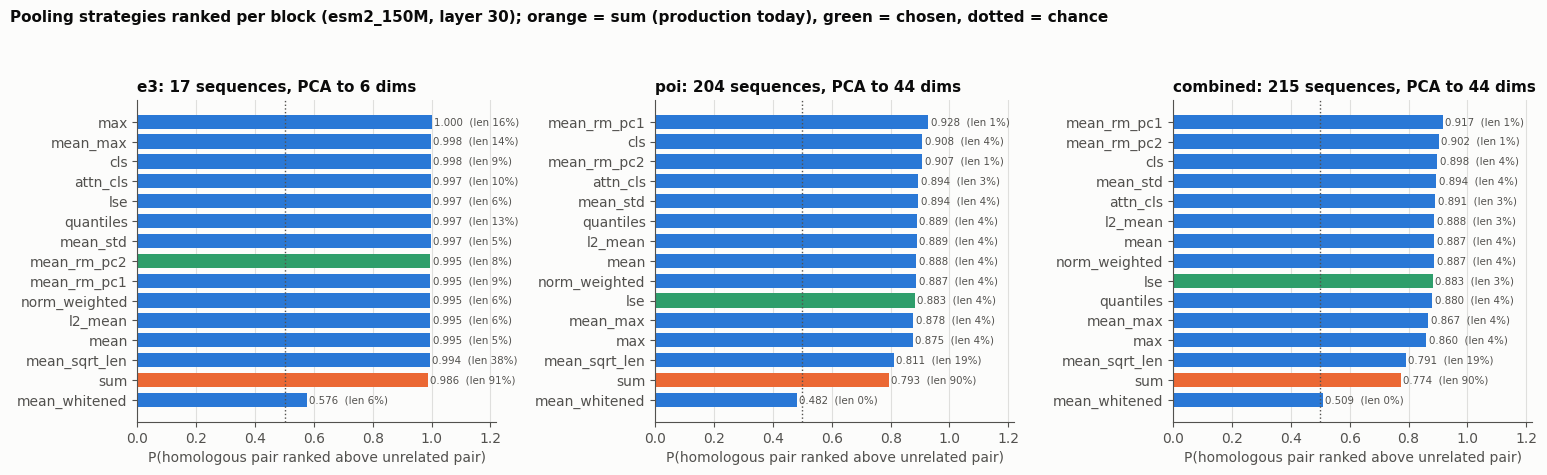

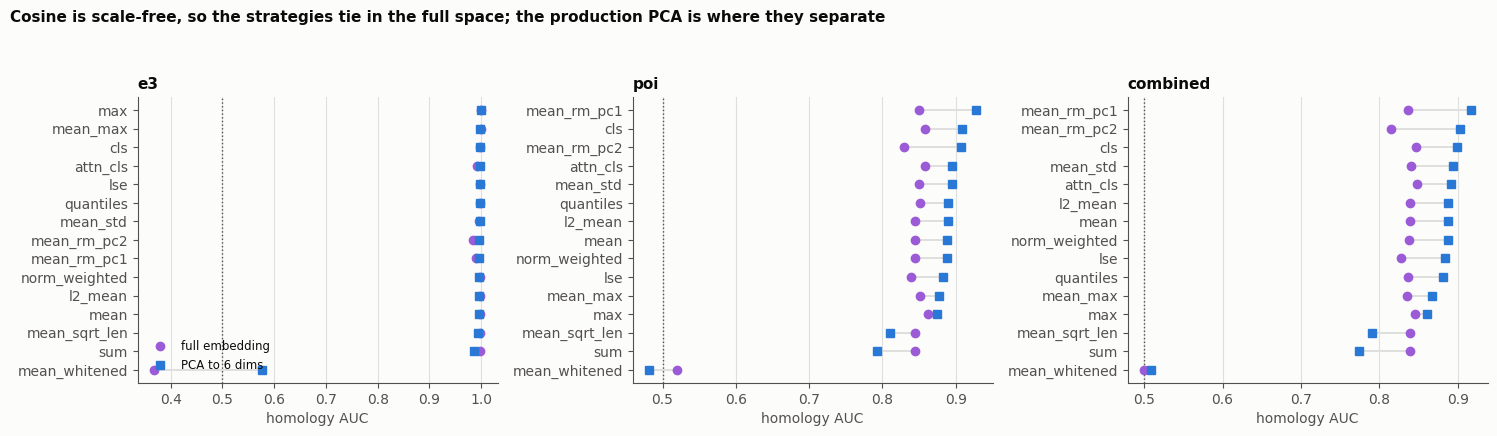

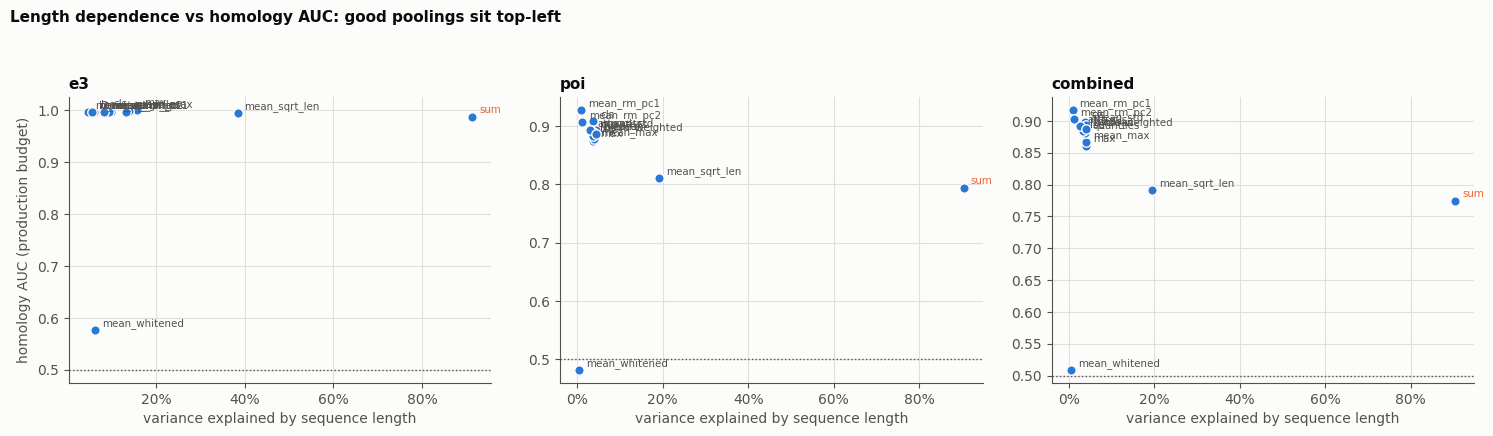

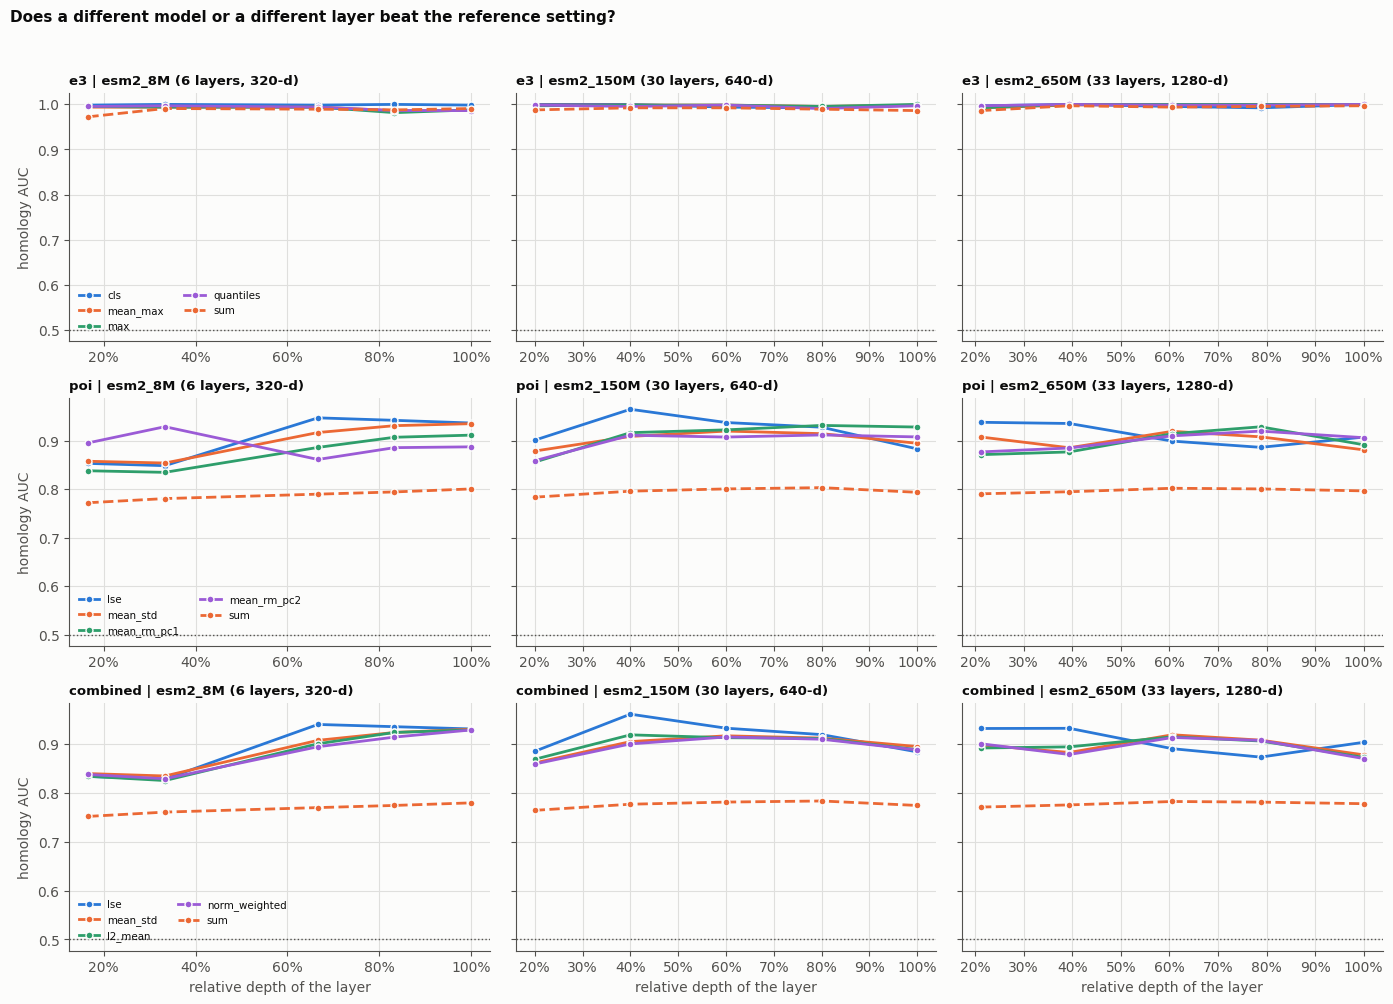

In [15]:
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#dfdfdd"
SERIES = ["#2a78d6", "#eb6834", "#2e9e6b", "#9b5bd6", "#d6b02a"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "savefig.dpi": 150,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.edgecolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})

def plot_strategy_ranking(path):
    """Homology AUC per strategy at the production budget, one panel per block; sum and the winner marked."""
    fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.8))
    for ax, b in zip(axes, BLOCKS):
        t = HEADLINE[HEADLINE["block"] == b].sort_values("homology_auc_pca")
        colors = [SERIES[1] if s == "sum" else (SERIES[2] if s == WINNERS[b]["strategy"] else SERIES[0]) for s in t["strategy"]]
        ax.barh(range(len(t)), t["homology_auc_pca"], color=colors, height=0.72)
        ax.axvline(0.5, color=INK_2, lw=1, ls=":", zorder=4)
        ax.set_yticks(range(len(t)), t["strategy"])
        for i, (v, d) in enumerate(zip(t["homology_auc_pca"], t["length_r2"])):
            ax.text(v + 0.008, i, f"{v:.3f}  (len {d:.0%})", va="center", fontsize=7.4, color=INK_2)
        ax.set_xlim(0, 1.22)
        ax.set_xlabel("P(homologous pair ranked above unrelated pair)")
        ax.set_title(f"{b}: {len(VOCAB[b])} sequences, PCA to {PRODUCTION_DIMS[b]} dims")
        ax.grid(axis="y", visible=False)
    fig.suptitle(f"Pooling strategies ranked per block ({REFERENCE_MODEL}, layer {REF_LAYER}); orange = sum (production today), "
                 f"green = chosen, dotted = chance", x=0.005, ha="left", fontsize=11, fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.93])
    fig.savefig(path)
    plt.show()

def plot_full_vs_pca(path):
    """The same strategies scored in the full space and at the production budget: they separate only after PCA."""
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
    for ax, b in zip(axes, BLOCKS):
        t = HEADLINE[HEADLINE["block"] == b].sort_values("homology_auc_pca")
        y = np.arange(len(t))
        ax.plot(t["homology_auc"], y, "o", ms=6, color=SERIES[3], label="full embedding", zorder=3)
        ax.plot(t["homology_auc_pca"], y, "s", ms=6, color=SERIES[0], label=f"PCA to {PRODUCTION_DIMS[b]} dims", zorder=3)
        for i, (a, c) in enumerate(zip(t["homology_auc"], t["homology_auc_pca"])):
            ax.plot([a, c], [i, i], color=GRID, lw=1.4, zorder=1)
        ax.set_yticks(y, t["strategy"])
        ax.axvline(0.5, color=INK_2, lw=1, ls=":")
        ax.set_xlabel("homology AUC")
        ax.set_title(b)
        ax.grid(axis="y", visible=False)
        if b == BLOCKS[0]:
            ax.legend(fontsize=8.5, loc="lower left")
    fig.suptitle("Cosine is scale-free, so the strategies tie in the full space; the production PCA is where they separate",
                 x=0.005, ha="left", fontsize=11, fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.93])
    fig.savefig(path)
    plt.show()

def plot_tradeoff(path):
    """Length dependence against homology AUC: the trade-off sum pooling loses."""
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
    for ax, b in zip(axes, BLOCKS):
        t = HEADLINE[HEADLINE["block"] == b]
        ax.scatter(t["length_r2"], t["homology_auc_pca"], s=46, color=SERIES[0], zorder=3, edgecolor=SURFACE, linewidth=1)
        for _, r in t.iterrows():
            ax.annotate(r["strategy"], (r["length_r2"], r["homology_auc_pca"]), xytext=(5, 3), textcoords="offset points",
                        fontsize=7.4, color=SERIES[1] if r["strategy"] == "sum" else INK_2)
        ax.axhline(0.5, color=INK_2, lw=1, ls=":")
        ax.set_xlabel("variance explained by sequence length")
        ax.set_ylabel("homology AUC (production budget)" if b == BLOCKS[0] else None)
        ax.set_title(b)
        ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    fig.suptitle("Length dependence vs homology AUC: good poolings sit top-left", x=0.005, ha="left", fontsize=11, fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.93])
    fig.savefig(path)
    plt.show()

def plot_layers_and_models(path, n_top=4):
    """Homology AUC across relative depth, per model, for the leading strategies and for sum."""
    fig, axes = plt.subplots(len(BLOCKS), len(MODELS), figsize=(14, 3.4 * len(BLOCKS)), sharey="row")
    for r, b in enumerate(BLOCKS):
        shown = list(STRATEGY_RANKING[b].index[:n_top]) + (["sum"] if "sum" not in STRATEGY_RANKING[b].index[:n_top] else [])
        for c, m in enumerate(MODELS):
            ax = axes[r, c]
            sub = RESULTS[(RESULTS["block"] == b) & (RESULTS["model"] == m)]
            for color, s in zip(SERIES, shown):
                d = sub[sub["strategy"] == s].sort_values("layer_frac")
                ax.plot(d["layer_frac"], d["homology_auc_pca"], marker="o", ms=5, lw=2, label=s, mec=SURFACE,
                        color=SERIES[1] if s == "sum" else color, ls="--" if s == "sum" else "-")
            ax.axhline(0.5, color=INK_2, lw=1, ls=":")
            ax.set_title(f"{b} | {m} ({MODEL_DEPTH[m]} layers, {MODEL_DIM[m]}-d)", fontsize=9.5)
            ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
            if r == len(BLOCKS) - 1:
                ax.set_xlabel("relative depth of the layer")
            if c == 0:
                ax.set_ylabel("homology AUC")
            if c == 0:
                ax.legend(fontsize=7.4, ncol=2, loc="lower left")      # each row shows its own block's leading strategies
    fig.suptitle("Does a different model or a different layer beat the reference setting?", x=0.005, ha="left", fontsize=11, fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    fig.savefig(path)
    plt.show()

plot_strategy_ranking(OUT_DIR / "01_strategy_ranking.png")
plot_full_vs_pca(OUT_DIR / "02_full_vs_pca.png")
plot_tradeoff(OUT_DIR / "03_length_vs_homology.png")
plot_layers_and_models(OUT_DIR / "04_layers_and_models.png")

In [16]:
# ----- test: results -----------------------------------------------------------------------------------------------------
assert len(RESULTS) == len(VARIANTS) and RESULTS.duplicated(["block", "model", "layer", "strategy"]).sum() == 0
assert set(RESULTS["block"]) == set(BLOCKS) and set(RESULTS["model"]) == set(MODELS) and set(RESULTS["strategy"]) == set(STRATEGIES)
assert RESULTS[["homology_auc_pca", "homology_auc", "length_r2", "dims90", "mean_cos"]].notna().all().all()
assert RESULTS["homology_auc_pca"].between(0, 1).all() and RESULTS["length_r2"].between(0, 1).all()
assert RESULTS_PATH.is_file() and len(pd.read_csv(RESULTS_PATH)) == len(RESULTS)

# the matched-budget column really is the production budget (or the rank limit of a small block)
for b in BLOCKS:
    want = min(PRODUCTION_DIMS[b], len(VOCAB[b]) - 1)
    assert (RESULTS.loc[RESULTS["block"] == b, "pca_dim"] <= want).all()
    assert (RESULTS.loc[(RESULTS["block"] == b) & (RESULTS["dim"] >= want), "pca_dim"] == want).all()

# cosine is scale-free: sum, mean and l2_mean must tie in the FULL space (up to float32 rounding of mean vs sum),
# and that is precisely why the comparison is made at the production budget instead
for b in BLOCKS:
    h = HEADLINE[HEADLINE["block"] == b].set_index("strategy")
    for metric in ("homology_auc", "identity_rho"):
        assert abs(h.loc["mean", metric] - h.loc["sum", metric]) < 1e-6, (b, metric)
        assert abs(h.loc["l2_mean", metric] - h.loc["mean", metric]) < 1e-6, (b, metric)
    assert abs(h.loc["sum", "homology_auc_pca"] - h.loc["mean", "homology_auc_pca"]) > 1e-3, f"{b}: PCA must separate sum from mean"

# the defect this notebook exists for, and the saturation that motivates the AUC threshold
for b in BLOCKS:
    h = HEADLINE[HEADLINE["block"] == b].set_index("strategy")
    assert h.loc["sum", "length_r2"] > 0.5 and h["length_r2"].min() < 0.2, b
    assert h.loc["mean", "length_r2"] < h.loc["sum", "length_r2"] and h.loc["l2_mean", "length_r2"] < h.loc["sum", "length_r2"]
    assert h.loc["sum", "homology_auc_pca"] < h.loc["mean", "homology_auc_pca"], b
    assert (h["homology_auc_strict_pca"] > 0.99).mean() > 0.8, f"{b}: the strict threshold should saturate for nearly everything"

# the selection rule: resolvable blocks rank on the AUC, saturated ones fall back, and the model never moves
assert 0 < SATURATION_SPREAD < 0.2 and 0 < LENGTH_GUARD < 1
assert set(RESULTS["depth_index"]) == set(range(len(LAYER_FRACTIONS)))
for b in BLOCKS:
    w = WINNERS[b]
    assert w["strategy"] in STRATEGIES and w["model"] == REFERENCE_MODEL and w["layer"] == LAYERS[REFERENCE_MODEL][w["depth_index"]]
    assert w["resolvable"] == (w["spread"] >= SATURATION_SPREAD)
    if w["resolvable"]:
        assert w["strategy"] == STRATEGY_RANKING[b].index[0]
        # a median over 15 cells must not hang on one of them: dropping the winner's best cell keeps it on top
        sub = RESULTS[RESULTS["block"] == b]
        without = sub.drop(index=sub[sub["strategy"] == w["strategy"]][SELECTION_METRIC].idxmax())
        assert without.groupby("strategy")[SELECTION_METRIC].median().idxmax() == w["strategy"], b
        # the chosen depth is the best of the three-model averages
        by_depth = sub[sub["strategy"] == w["strategy"]].groupby("depth_index")[SELECTION_METRIC].mean()
        assert w["depth_index"] == int(by_depth.idxmax())
    else:
        assert w["layer"] == REF_LAYER, "a saturated block must stay at the production setting"
        med = RESULTS[RESULTS["block"] == b].groupby("strategy").agg(rho=("identity_rho_pca", "median"), length=("length_r2", "median"))
        assert med.loc[w["strategy"], "length"] <= LENGTH_GUARD
        assert w["strategy"] == med[med["length"] <= LENGTH_GUARD]["rho"].idxmax()
    assert w["strategy"] != "sum", f"{b}: the rule selected the pooling this notebook set out to replace"

# e3 is the block that cannot resolve: that is a finding, not an accident, and the rule must notice it
assert not WINNERS["e3"]["resolvable"], "the E3 block was expected to saturate on 5 homologous pairs"
assert WINNERS["poi"]["resolvable"] and WINNERS["combined"]["resolvable"]
for name in ["01_strategy_ranking.png", "02_full_vs_pca.png", "03_length_vs_homology.png", "04_layers_and_models.png"]:
    assert (OUT_DIR / name).stat().st_size > 10_000, name
print(f"results: OK ({len(RESULTS):,} variants scored; sum length-dominated and beaten after PCA in all {len(BLOCKS)} blocks; "
      f"winner stable when its best cell is removed)")

results: OK (675 variants scored; sum length-dominated and beaten after PCA in all 3 blocks; winner stable when its best cell is removed)


## 7. Cached embeddings for the winners

For each block — **e3**, **poi** and **combined** — the winning (model, layer, strategy) is written to `TACKAI_CACHE` in the same `.npz` layout as the other TACK embeddings: the full table, the PCA-compressed
table, and the fitted PCA. The number of components follows the rule of `context_embeddings.ipynb`: the fewest that explain 90 % of the variance **and** keep 0.95 of the similarity structure
(the second criterion is what stops a length-dominated table from collapsing to one component).

The file names carry the model, the layer and the pooling, so these files sit next to the `pooling=sum` ones rather than overwriting them, and a later run with another winner writes new files.

In [17]:
class StoredEmbedding(EmbeddingMixin):
    """Store for the precomputed vectors; saves and loads like the other TACK embeddings."""

    def _transform_batch(self, keys):
        raise KeyError(f"no cached embedding for {keys[:3]}")

def similarity_preservation(X):
    """Variance and similarity structure kept by the first k PCA components, for k = 1 ... min(n - 1, d)."""
    kmax = min(len(X) - 1, X.shape[1])
    pca = PCA(n_components=kmax, svd_solver="full").fit(X)
    Z, upper = pca.transform(X), np.triu_indices(len(X), k=1)
    full = cosine_matrix(X - pca.mean_)[upper]
    rows = []
    for k in range(1, kmax + 1):
        rows.append({"dims": k, "variance": pca.explained_variance_ratio_[:k].sum(),
                     "similarity_rho": spearmanr(cosine_matrix(Z[:, :k] @ pca.components_[:k])[upper], full).statistic})
    return pd.DataFrame(rows)

def choose_dims(table, variance_target, similarity_target):
    """Fewest components reaching the variance target and, when given, the similarity target."""
    ok = table["variance"] >= variance_target - 1e-12
    if similarity_target is not None:
        ok &= table["similarity_rho"] >= similarity_target - 1e-12
    return int(table.loc[ok, "dims"].min())

def winner_stem(block, model_tag, layer, strategy):
    return f"protein_embeddings_esm_model={MODELS[model_tag].replace('/', '-')}_layer={layer}_pooling={strategy}_window={WINDOW}_block={block}"

WINNER_FILES, WINNER_INFO = {}, {}
for b in BLOCKS:
    mtag, layer, strategy = WINNERS[b]["model"], WINNERS[b]["layer"], WINNERS[b]["strategy"]
    block = b
    X = table_for(block, mtag, layer, strategy)
    uniq = np.sort(np.unique(X, axis=0, return_index=True)[1])
    k = choose_dims(similarity_preservation(X[uniq]), VARIANCE_TARGET, SIMILARITY_TARGET)
    pca = PCA(n_components=k, svd_solver="full").fit(X[uniq])
    full = {s: v.astype(np.float32) for s, v in zip(VOCAB[b], X)}
    reduced = {s: v.astype(np.float32) for s, v in zip(VOCAB[b], pca.transform(X))}

    stem = winner_stem(block, mtag, layer, strategy)
    files = {"full": f"{stem}.npz", "pca": f"{stem}_pca{k}.npz", "pca_model": f"{stem}_pca{k}_model.npz"}
    StoredEmbedding(embeddings=full, filename=files["full"], cache_dir=CACHE_DIR).save()
    StoredEmbedding(embeddings=reduced, filename=files["pca"], cache_dir=CACHE_DIR).save()
    np.savez(CACHE_DIR / files["pca_model"], mean_=pca.mean_.astype(np.float32), components_=pca.components_.astype(np.float32),
             explained_variance_ratio_=pca.explained_variance_ratio_.astype(np.float32))
    WINNER_FILES[b] = files
    WINNER_INFO[b] = {"model": mtag, "model_name": MODELS[mtag], "layer": int(layer), "pooling": strategy, "window": WINDOW,
                      "n_sequences": len(VOCAB[b]), "embedding_dim": int(X.shape[1]), "pca_dims": k,
                      "explained_variance": float(pca.explained_variance_ratio_.sum()),
                      "homology_auc_pca": float(RESULTS.query("block == @b and model == @mtag and layer == @layer and strategy == @strategy")["homology_auc_pca"].item()),
                      "selection_rule": WINNERS[b]["rule"], "block_resolvable": bool(WINNERS[b]["resolvable"]),
                      "files": files}
    print(f"{b}: {mtag} layer {layer} / {strategy} -> {X.shape[1]}-d, PCA {k} dims ({pca.explained_variance_ratio_.sum():.1%})")

META_FILE = "protein_pooling_meta.json"
META = {"notebook": "notebooks/protein_pooling_comparison.ipynb", "selected_on": SELECTION_METRIC, "homology_threshold": HOMOLOGY_THRESHOLD,
        "variance_target": VARIANCE_TARGET, "similarity_target": SIMILARITY_TARGET,
        "production_pca_dims": PRODUCTION_DIMS, "blocks": WINNER_INFO}
(CACHE_DIR / META_FILE).write_text(json.dumps(META, indent=1))
for name in [META_FILE] + [f for b in BLOCKS for f in WINNER_FILES[b].values()]:
    print(f"{(CACHE_DIR / name).stat().st_size / 1024:9.1f} KB  {name}")

e3: esm2_150M layer 30 / mean_rm_pc2 -> 640-d, PCA 7 dims (91.8%)


poi: esm2_150M layer 18 / lse -> 640-d, PCA 51 dims (90.3%)


combined: esm2_150M layer 18 / lse -> 640-d, PCA 52 dims (90.1%)
      2.6 KB  protein_pooling_meta.json
     66.1 KB  protein_embeddings_esm_model=facebook-esm2_t30_150M_UR50D_layer=30_pooling=mean_rm_pc2_window=1022_block=e3.npz
     24.0 KB  protein_embeddings_esm_model=facebook-esm2_t30_150M_UR50D_layer=30_pooling=mean_rm_pc2_window=1022_block=e3_pca7.npz
     20.8 KB  protein_embeddings_esm_model=facebook-esm2_t30_150M_UR50D_layer=30_pooling=mean_rm_pc2_window=1022_block=e3_pca7_model.npz
    855.9 KB  protein_embeddings_esm_model=facebook-esm2_t30_150M_UR50D_layer=18_pooling=lse_window=1022_block=poi.npz
    386.5 KB  protein_embeddings_esm_model=facebook-esm2_t30_150M_UR50D_layer=18_pooling=lse_window=1022_block=poi_pca51.npz
    131.0 KB  protein_embeddings_esm_model=facebook-esm2_t30_150M_UR50D_layer=18_pooling=lse_window=1022_block=poi_pca51_model.npz
    899.9 KB  protein_embeddings_esm_model=facebook-esm2_t30_150M_UR50D_layer=18_pooling=lse_window=1022_block=combined.npz
  

In [18]:
# ----- test: cached winners ----------------------------------------------------------------------------------------------
for b in BLOCKS:
    files, info = WINNER_FILES[b], WINNER_INFO[b]
    assert all((CACHE_DIR / f).is_file() and (CACHE_DIR / f).stat().st_size > 0 for f in files.values())
    assert f"pooling={info['pooling']}" in files["full"] and f"layer={info['layer']}" in files["full"] and f"block={b}" in files["full"]
    assert "pooling=sum_" not in files["full"] or info["pooling"] == "sum"

    full = StoredEmbedding(load_from_cache=True, filename=files["full"], cache_dir=CACHE_DIR)
    reduced = StoredEmbedding(load_from_cache=True, filename=files["pca"], cache_dir=CACHE_DIR)
    assert list(full.embeddings) == VOCAB[b] and list(reduced.embeddings) == VOCAB[b]
    assert full.shape() == (info["embedding_dim"],) and reduced.shape() == (info["pca_dims"],)
    X = table_for(b, WINNERS[b]["model"], WINNERS[b]["layer"], WINNERS[b]["strategy"])
    assert np.allclose(np.stack(list(full.embeddings.values())), X, rtol=1e-5, atol=1e-4)

    # the saved PCA reproduces the compressed table from the full one alone
    side = np.load(CACHE_DIR / files["pca_model"])
    assert set(side.files) == {"mean_", "components_", "explained_variance_ratio_"}
    assert side["components_"].shape == (info["pca_dims"], info["embedding_dim"])
    assert side["explained_variance_ratio_"].sum() >= VARIANCE_TARGET - 1e-4
    Z = np.stack(list(reduced.embeddings.values()))
    projected = (np.stack(list(full.embeddings.values())).astype(np.float64) - side["mean_"]) @ side["components_"].T
    assert np.allclose(projected, Z, rtol=1e-3, atol=1e-3 * max(1.0, np.abs(Z).max()))

    # the PCA size obeys both targets, and the compressed table still beats sum on the criterion it was chosen for
    pres = similarity_preservation(X[np.sort(np.unique(X, axis=0, return_index=True)[1])])
    k = info["pca_dims"]
    assert pres.set_index("dims").loc[k, "variance"] >= VARIANCE_TARGET - 1e-9
    assert pres.set_index("dims").loc[k, "similarity_rho"] >= SIMILARITY_TARGET - 1e-9
    assert all(pres.set_index("dims").loc[j, "variance"] < VARIANCE_TARGET - 1e-9
               or pres.set_index("dims").loc[j, "similarity_rho"] < SIMILARITY_TARGET - 1e-9 for j in range(1, k))

# the winner is at least as good as sum at the reference setting on the selection criterion
for b in BLOCKS:
    sum_score = HEADLINE[(HEADLINE["block"] == b) & (HEADLINE["strategy"] == "sum")]["homology_auc_pca"].item()
    assert WINNER_INFO[b]["homology_auc_pca"] > sum_score, (b, WINNER_INFO[b]["homology_auc_pca"], sum_score)

# the files written for the three blocks are distinct, and the production sum files are untouched
assert len({f for b in BLOCKS for f in WINNER_FILES[b].values()}) == 3 * len(BLOCKS)
meta = json.loads((CACHE_DIR / META_FILE).read_text())
assert set(meta["blocks"]) == set(BLOCKS) and all(meta["blocks"][b]["files"] == WINNER_FILES[b] for b in BLOCKS)
assert meta["selected_on"] == SELECTION_METRIC
print(f"cached winners: OK ({3 * len(BLOCKS) + 1} files; every table reloads and its PCA reproduces the compressed vectors)")

cached winners: OK (10 files; every table reloads and its PCA reproduces the compressed vectors)


## 8. Conclusions

### 8.1 What the comparison found

**Sum pooling is the worst non-degenerate strategy in every block, and it should be replaced.** Sequence length explains **90 %** of the variance of its table (`length_r2` 0.904 for POI, 0.913 for E3), it collapses
to a *single* component at 90 % variance, and at the production feature budget it ranks homologous pairs above unrelated ones with AUC **0.793** (POI) against 0.888 for plain `mean`.

**The damage is done by the PCA, not by the pooling on its own** — this is the part worth internalising. Cosine similarity is invariant to scaling each vector, and `sum`, `mean` and `l2_mean` differ only by a
per-sequence scalar, so in the **full 640-d space all three are literally identical**: AUC 0.845 for every one of them. PCA is not row-scale invariant: it centres the table, the length-driven magnitude becomes its
leading component, and the 44 components handed to the model are then largely a length coordinate. Any diagnostic run on raw embeddings will therefore declare sum pooling healthy; it is only broken where it is used.

| strategy | POI full-space AUC | POI AUC after PCA to 44 | length_r2 |
|---|---|---|---|
| `sum` (production) | 0.845 | **0.793** | 0.904 |
| `mean` | 0.845 | 0.888 | 0.045 |
| `l2_mean` | 0.845 | 0.889 | 0.037 |

Three further findings:

* **`mean_sqrt_len` is nearly as bad as `sum`** (AUC 0.811, `length_r2` 0.19): dividing by `sqrt(L)` removes only part of a scaling that grows like `L`.
* **`mean_whitened` destroys the representation** — AUC 0.48–0.55, i.e. at or below chance, and same-gene retrieval falls from 0.96 to 0.15. Whitening rescales every principal direction to unit variance, so the
  noise directions are amplified to the same weight as the informative ones. It is in the comparison because it looked reasonable a priori; it should not be used.
* **The E3 block cannot resolve this question.** With 17 sequences it has 5 homologous pairs, and 13 of 15 strategies score between 0.989 and 1.000 — including `sum`. The notebook detects this
  (`best - median = 0.003 < SATURATION_SPREAD`) and falls back to the global correlation rather than ranking noise. **Any E3 pooling claim rests on the length diagnostic, not on the retrieval one.**

### 8.2 What to change

| block | chosen | AUC at the production budget | against `sum` |
|---|---|---|---|
| **poi** | `lse` at `esm2_150M` layer 18 | 0.937 [0.877, 0.996] | 0.793 |
| **combined** | `lse` at `esm2_150M` layer 18 | 0.932 [0.877, 0.999] | 0.774 |
| **e3** | `mean_rm_pc2` at `esm2_150M` layer 30 | not resolvable; chosen on `identity_rho_pca` and `length_r2` | — |

**If you change one thing, change `sum` to `mean` (or `l2_mean`).** It needs no new code path, is already in `ProteinEmbedding`, and recovers most of the gap: 0.888 against 0.793 for POI, with `length_r2` falling from
0.90 to 0.045. `lse` adds a further ~0.05 and is a six-line addition (§8.3).

Two caveats on the winner, stated plainly:

* `mean_rm_pc1` scores **higher than `lse` at the last layer** (0.928 vs 0.883 for POI) but is less consistent across depths, so the median-across-cells rule prefers `lse` (median 0.927 vs 0.907). If you intend to
  keep the last layer, `mean_rm_pc1` is the better choice — but it is a *table-level* transform fitted on the whole vocabulary, so it belongs next to the PCA in the datamodule, not in `_pool_residue_embeddings`.
* The chosen layer 18 beats the last layer by 0.054 for `lse`, and the bootstrap interval [0.877, 0.996] comfortably contains the last layer's 0.883. **This is a suggestive difference, not an established one.**

### 8.3 Model and layer

**Model size does not matter here.** The best strategy of each model lands within 0.01–0.02 AUC of the others, far inside the bootstrap intervals. `esm2_650M` costs about 10x the compute of `esm2_150M` and buys nothing
measurable on this criterion; `esm2_8M` is not measurably worse. Staying on `esm2_150M` is the right call, and the notebook never switches model for that reason.

**Layer matters mildly, and in a model-dependent way.** Averaged over the three models the best relative depth is 60 % (0.928) against 0.909 at the last layer, but the shape differs per model: `esm2_150M` peaks at
40–60 %, `esm2_650M` at ~20 %, while `esm2_8M` is best at its last layer. So "intermediate layers carry more structure than the final one" holds for the two larger models and is worth a look, but it does not transfer
as a fixed fraction between checkpoints.

### 8.4 What this does *not* establish

Every criterion here is unsupervised, as requested. A pooling that ranks homologues better is a better *protein* representation; it does not follow that it predicts degradation better, because the degradation label
may depend on protein properties that sequence identity does not track. The cheap way to close that gap is a scaffold-grouped CV with the POI block swapped between `sum` and the winner, reusing the harness in
`fusion_comparison.ipynb` — that is the natural next step, and it is not done here.

Two smaller limits: the pairwise identity comes from a global BLASTP-scored alignment, which is a weak notion of relatedness for remote homologues sharing a fold at low identity; and the windowing of long sequences
(40 of 204 targets exceed 1022 residues) prevents attention across window boundaries, which affects every strategy equally but is not free.

### 8.1 Ready-to-paste: the new poolings in `ProteinEmbedding`

`_pool_residue_embeddings` currently supports `mean`, `sum`, `max`, `cls` and `mean_sqrt_len`. The block below adds the strategies compared here that are **pure functions of one sequence's per-residue
matrix** — the table-level ones (`mean_rm_pc1`, `mean_rm_pc2`, `mean_whitened`) cannot go there, because they are fitted on a whole vocabulary; they belong next to the PCA in the datamodule, after all
sequences have been embedded.

Replace the body of `ProteinEmbedding._pool_residue_embeddings` with:

```python
    def _pool_residue_embeddings(self, emb: np.ndarray) -> np.ndarray:
        """ Pool per-residue embeddings (L, D) to a sequence-level vector.

        Args:
            emb: Per-residue embeddings of shape (L, D).

        Returns:
            Pooled embeddings of shape (D,), or (2 * D,) / (5 * D,) for the concatenating strategies.
        """
        if self.residue_pooling == "mean":
            return np.mean(emb, axis=0)
        elif self.residue_pooling == "sum":
            return np.sum(emb, axis=0)
        elif self.residue_pooling == "max":
            return np.max(emb, axis=0)
        elif self.residue_pooling == "cls":
            return emb[0]
        elif self.residue_pooling == "mean_sqrt_len":
            return np.mean(emb, axis=0) / np.sqrt(emb.shape[0])
        elif self.residue_pooling == "l2_mean":
            # Length-invariant: identical to the L2-normalised sum, which differs only by the scalar L.
            v = np.mean(emb, axis=0)
            norm = np.linalg.norm(v)
            return v if norm == 0 else v / norm
        elif self.residue_pooling == "mean_max":
            return np.concatenate([np.mean(emb, axis=0), np.max(emb, axis=0)])
        elif self.residue_pooling == "mean_std":
            return np.concatenate([np.mean(emb, axis=0), np.std(emb, axis=0)])
        elif self.residue_pooling == "quantiles":
            return np.quantile(emb, [0.0, 0.25, 0.5, 0.75, 1.0], axis=0).ravel()
        elif self.residue_pooling == "lse":
            # Smooth maximum; tau -> 0 recovers max, tau -> inf recovers mean.
            tau = getattr(self, "lse_tau", 1.0)
            return tau * (scipy.special.logsumexp(emb / tau, axis=0) - np.log(emb.shape[0]))
        elif self.residue_pooling == "norm_weighted":
            w = np.linalg.norm(emb, axis=1)
            return (w / w.sum()) @ emb if w.sum() > 0 else np.mean(emb, axis=0)
        else:
            raise ValueError(f"Unsupported residue pooling method: {self.residue_pooling}")
```

and widen the two `Literal` hints (`residue_pooling` on `ProteinEmbedding.__init__`, and `poi_residue_pooling` / `ligase_residue_pooling` on `DegradationComplexDataModule.__init__`) to:

```python
Literal["mean", "sum", "max", "cls", "mean_sqrt_len", "l2_mean", "mean_max", "mean_std", "quantiles", "lse", "norm_weighted"]
```

`attn_cls` is **not** in this list: it needs the model's attention matrix, which a per-residue embedding file does not carry. It would have to be computed in `_encode_with_transformer`, where the forward
pass happens, by requesting `output_attentions=True`.

**Before switching a config**, note that changing `poi_residue_pooling` / `ligase_residue_pooling` changes the vectors but **not** the embedding file names in `TACKAI_CACHE` (`ProteinEmbedding` puts
`pooling` in its default name, but the production configs pass an explicit `embeddings_file`). Delete or rename the affected caches, or the old pooling's vectors will be loaded under the new setting.

In [19]:
# ===== Standalone cell: load the cached winning embeddings. Run it in a fresh kernel; no earlier cell is required. =====
import json
from pathlib import Path

import numpy as np
import pandas as pd
from dotenv import load_dotenv, find_dotenv

from tackai.data.utils import get_cache_dir

load_dotenv(find_dotenv())                       # TACKAI_CACHE from .env when present, otherwise ~/.cache/tackai
CACHE_DIR = Path(get_cache_dir())
META = json.loads((CACHE_DIR / "protein_pooling_meta.json").read_text())   # winner per block: model, layer, pooling, file names
_TABLES = {}

def load_table(block, reduced=False):
    """Cached embeddings of a block as ``{sequence: vector}``.

    Args:
        block: ``"e3"`` (recruiter sequences), ``"poi"`` (target sequences) or ``"combined"`` (both in one shared space).
        reduced: ``True`` for the PCA-compressed vectors, ``False`` for the full ones.
    """
    if (block, reduced) not in _TABLES:
        _TABLES[(block, reduced)] = dict(np.load(CACHE_DIR / META["blocks"][block]["files"]["pca" if reduced else "full"]))
    return _TABLES[(block, reduced)]

def embed(block, sequences, reduced=False):
    """Look up the cached vector of every sequence, in order, as a float32 array of shape (len(sequences), dim).

    Sequences are looked up by their stripped string; an unknown sequence raises ``KeyError`` rather than getting a
    silent substitute. Sanitise non-standard residue codes first with ``tackai...protein_embeddings.sanitize_sequence``.
    """
    table = load_table(block, reduced)
    rows = [table[str(s).strip()] for s in sequences]
    dim = META["blocks"][block]["pca_dims" if reduced else "embedding_dim"]
    return np.stack(rows) if rows else np.empty((0, dim), dtype=np.float32)

def project(block, X):
    """Project full-dimension vectors of a block with that block's cached PCA."""
    side = np.load(CACHE_DIR / META["blocks"][block]["files"]["pca_model"])
    return (np.asarray(X, dtype=np.float64) - side["mean_"]) @ side["components_"].T

# ----- example: feature matrices for the first rows of TACKv2 -----------------------------------------------------------------
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "yaochen").is_dir())
rows = pd.read_csv(root / "data" / "yaochen" / "TACKv2.csv", usecols=["Recruiter_Sequence", "Degradation_Target_Sequence"],
                   dtype="string", nrows=500).dropna()
for block, column in [("e3", "Recruiter_Sequence"), ("poi", "Degradation_Target_Sequence"), ("combined", "Degradation_Target_Sequence")]:
    info = META["blocks"][block]
    X = embed(block, rows[column], reduced=True)
    assert X.shape == (len(rows), info["pca_dims"]) and np.isfinite(X).all()
    print(f"{block:9s} {str(X.shape):12s} {info['model']} layer {info['layer']} / {info['pooling']}  "
          f"(full {info['embedding_dim']}-d, PCA keeps {info['explained_variance']:.1%})")

first = rows["Degradation_Target_Sequence"].iloc[0]
assert np.allclose(project("poi", load_table("poi")[first][None]), load_table("poi", reduced=True)[first], rtol=1e-3, atol=1e-3)

e3        (462, 7)     esm2_150M layer 30 / mean_rm_pc2  (full 640-d, PCA keeps 91.8%)
poi       (462, 51)    esm2_150M layer 18 / lse  (full 640-d, PCA keeps 90.3%)
combined  (462, 52)    esm2_150M layer 18 / lse  (full 640-d, PCA keeps 90.1%)
